# Aporte lineal, no lineal y del aprendizaje por gradiente en la detección de intrusos (NSL-KDD)

**Pregunta:** ¿cuánto aporta un autoencoder entrenado por descenso del gradiente frente a métodos clásicos de reconstrucción, en la detección de anomalías en NSL-KDD?

Los tres métodos comparten el mismo esquema (comprimir a $k$ dimensiones, reconstruir y usar el error de reconstrucción como *score*) y difieren en un factor cada vez:

| Método | Representación | Cómo se obtiene |
|---|---|---|
| PCA | Lineal | Solución cerrada (vectores propios de la covarianza) |
| Kernel PCA (RBF) | No lineal, **fija** (la define el kernel) | Solución cerrada (vectores propios de la matriz kernel) |
| AE (3, *w*) | No lineal, **aprendida** | Descenso del gradiente (Adam) |

El AE (3, *w*) (`entrada → w → z → w → salida`) tiene la misma estructura que kernel PCA: una capa oculta a cada lado de la latente. Kernel PCA usa *m* neuronas RBF fijas (una por punto de la submuestra); el AE usa *w* neuronas ReLU aprendidas.

**Comparaciones (diferencia de AUC en test, bootstrap pareado):**

| Comparación | Qué mide |
|---|---|
| KPCA(m) − PCA(m) | No linealidad fija, mismos datos |
| AE(m) − KPCA(m) | Representación aprendida por gradiente frente a fija, mismos datos |
| AE(completo) − AE(m) | Aporte de poder usar todos los datos |
| AE(completo) − PCA(completo) | Aporte total del deep learning |

## Decisiones del diseño
- Mismo split y mismo preprocesamiento del notebook anterior (`script.ipynb`). El preprocesamiento se ajusta **una vez** con todos los normales del train: todos los métodos ven el mismo espacio de entrada.
- Submuestra *m* = 10 000 normales, estratificada por `service` (servicios con < 10 registros agrupados en "otros"). Es la misma para PCA, kernel PCA y AE.
- Rejillas: $k = z \in \{2, 4, 6, 8, 12, 16\}$; $w \in \{32, 64, 128, 256\}$; $\gamma = \gamma_0 \times \{0.1, 0.3, 1, 3, 10\}$ con $\gamma_0$ por heurística de la mediana; `alpha` (pre-imagen) $\in \{0.1, 1\}$.
- AE: batch 512, Adam (lr = 1e-4, weight decay = 1e-5), presupuesto máximo de **12 000 actualizaciones** en ambas condiciones de datos. AUC de validación cada ~200 actualizaciones (cada 2 épocas con datos completos, cada 10 con la submuestra), *early stopping* con paciencia de 5 evaluaciones y restauración de los mejores pesos.
- *w* se elige con una semilla (42) por condición de datos; luego se corren las semillas 43–46 con el *w* elegido.
- Análisis principal **a igual capacidad** (*k* = *z*), sin elegir *k*: el aporte es el promedio de Δ AUC sobre la rejilla. Kernel PCA con γ = γ₀ y `alpha` = 1 fijados a priori. La selección por AUC de validación se reporta como resultado secundario, porque la validación está saturada.
- Umbral: z-score con los normales de validación y barrido por MCC (igual que antes).
- Métrica principal: AUC en test. Secundaria: MCC. Incertidumbre: bootstrap pareado (1 000 remuestreos) sobre test.
- PCA y kernel PCA implementados en TensorFlow (GPU), validados contra sklearn. Costo: tiempo de ajuste, tiempo de inferencia y memoria, todo en GPU.
- El AE (5, 64) **no se vuelve a correr**: se reportan sus resultados del notebook anterior como referencia de mayor profundidad.

In [1]:
import gc
import math
import os
import random
import time
from pathlib import Path

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import numpy as np
import pandas as pd

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA, KernelPCA
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             matthews_corrcoef, roc_auc_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import Model, layers
from tensorflow.keras.optimizers import Adam

import matplotlib.pyplot as plt
import seaborn as sns

# La GPU reserva memoria a medida que la necesita (la matriz kernel ocupa cientos de MB)
for gpu in tf.config.list_physical_devices("GPU"):
    tf.config.experimental.set_memory_growth(gpu, True)
print("GPU:", tf.config.list_physical_devices("GPU"))

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")

I0000 00:00:1793990739.144981 2270956 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1793990740.997838 2270956 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Configuración del experimento
`APORTES_RAPIDO=1` (variable de entorno) corre una versión reducida de punta a punta, para verificar que el notebook funciona antes del experimento completo. Sus resultados se guardan en carpetas aparte.

In [2]:
RAPIDO = os.environ.get("APORTES_RAPIDO") == "1"

GRID_Z = [2, 4, 6, 8, 12, 16]             # k de PCA / kernel PCA y z del AE
GRID_W = [32, 64, 128, 256]               # neuronas de la capa oculta del AE (3, w)
FACTORES_GAMMA = [0.1, 0.3, 1, 3, 10]     # gamma = gamma_0 x factor
GRID_ALPHA = [0.1, 1.0]                   # regularización de la pre-imagen de kernel PCA
M_SUB = 10_000                            # tamaño de la submuestra
SEMILLAS = [SEED + i for i in range(5)]   # 42-46

BATCH = 512
LR, WEIGHT_DECAY = 1e-4, 1e-5
PRESUPUESTO_PASOS = 12_000                # actualizaciones máximas por corrida
PASOS_ENTRE_EVAL = 200                    # AUC de validación cada ~200 actualizaciones
PACIENCIA = 5                             # evaluaciones sin mejora antes de detener
N_BOOTSTRAP = 1_000

if RAPIDO:
    GRID_Z, GRID_W, FACTORES_GAMMA, GRID_ALPHA = [2, 8], [32, 64], [0.3, 1], [0.1]
    M_SUB, SEMILLAS, PRESUPUESTO_PASOS, N_BOOTSTRAP = 3_000, [42, 43], 1_200, 50

DATA_DIR = Path("data") / "nslkdd"
RESULTADOS_DIR = Path("resultados") / ("aportes_rapido" if RAPIDO else "aportes")
FIGURAS_DIR = Path("figuras") / "aportes_rapido" if RAPIDO else Path("figuras")
SCORES_DIR = RESULTADOS_DIR / "scores"
MODELOS_DIR = RESULTADOS_DIR / "modelos"
for d in [RESULTADOS_DIR, FIGURAS_DIR, SCORES_DIR, MODELOS_DIR]:
    d.mkdir(parents=True, exist_ok=True)
print("Modo rápido:", RAPIDO, "| resultados en", RESULTADOS_DIR)

Modo rápido: False | resultados en resultados/aportes


# Datos
Mismo split que `script.ipynb`: validación = 20 % de `KDDTrain+` estratificado por tipo de ataque (semilla 42); test = `KDDTest+`.

In [3]:
feature_cols = []
with open(DATA_DIR / "KDDTrain+.arff") as f:
    for line in f:
        line = line.strip()
        if line.lower().startswith("@attribute"):
            feature_cols.append(line.split()[1].strip("'"))
        elif line.lower().startswith("@data"):
            break
NSLKDD_COLS = feature_cols[:-1] + ["label", "difficulty"]

NSLKDD_data = pd.read_csv(DATA_DIR / "KDDTrain+.txt", header=None, names=NSLKDD_COLS)
NSLKDD_test = pd.read_csv(DATA_DIR / "KDDTest+.txt", header=None, names=NSLKDD_COLS)
NSLKDD_data["attack"] = (NSLKDD_data["label"] != "normal").astype(int)
NSLKDD_test["attack"] = (NSLKDD_test["label"] != "normal").astype(int)
NSLKDD_train, NSLKDD_validation = train_test_split(
    NSLKDD_data, test_size=.2, random_state=SEED, stratify=NSLKDD_data["label"])

FEATURES = NSLKDD_COLS[:41]
CAT_COLS = ["protocol_type", "service", "flag"]
NUM_COLS = [c for c in FEATURES if c not in CAT_COLS]

X_train, y_train = NSLKDD_train[FEATURES], NSLKDD_train["attack"].to_numpy()
X_val, y_val = NSLKDD_validation[FEATURES], NSLKDD_validation["attack"].to_numpy()
X_test, y_test = NSLKDD_test[FEATURES], NSLKDD_test["attack"].to_numpy()

for nombre, X, y in [("train", X_train, y_train), ("val", X_val, y_val), ("test", X_test, y_test)]:
    print(f"{nombre:>5}: {X.shape} | % ataques = {y.mean():.3f}")

train: (100778, 41) | % ataques = 0.465
  val: (25195, 41) | % ataques = 0.465
 test: (22544, 41) | % ataques = 0.569


In [4]:
CATEGORY_ORDER = ["DoS", "Probe", "R2L", "U2R"]
ATTACK_CATEGORY = {
    "back": "DoS", "land": "DoS", "neptune": "DoS", "pod": "DoS", "smurf": "DoS",
    "teardrop": "DoS", "apache2": "DoS", "mailbomb": "DoS", "processtable": "DoS", "udpstorm": "DoS",
    "ipsweep": "Probe", "nmap": "Probe", "portsweep": "Probe", "satan": "Probe", "mscan": "Probe", "saint": "Probe",
    "ftp_write": "R2L", "guess_passwd": "R2L", "imap": "R2L", "multihop": "R2L", "phf": "R2L", "spy": "R2L",
    "warezclient": "R2L", "warezmaster": "R2L", "named": "R2L", "sendmail": "R2L", "snmpgetattack": "R2L",
    "snmpguess": "R2L", "xlock": "R2L", "xsnoop": "R2L", "worm": "R2L",
    "buffer_overflow": "U2R", "loadmodule": "U2R", "perl": "U2R", "rootkit": "U2R",
    "httptunnel": "U2R", "ps": "U2R", "sqlattack": "U2R", "xterm": "U2R",
}
CATEGORIA_TEST = NSLKDD_test["label"].map(ATTACK_CATEGORY).fillna("Normal").to_numpy()
NUEVO_TEST = ((NSLKDD_test["attack"] == 1)
              & ~NSLKDD_test["label"].isin(NSLKDD_train["label"].unique())).to_numpy()
assert set(CATEGORIA_TEST[y_test == 1]) <= set(CATEGORY_ORDER), "hay ataques de test sin categoría"
print(pd.Series(CATEGORIA_TEST).value_counts(), "\nAtaques solo en test:", NUEVO_TEST.sum())

Normal    9711
DoS       7458
R2L       2754
Probe     2421
U2R        200
Name: count, dtype: int64 
Ataques solo en test: 3750


# Preprocesamiento común
El mismo del autoencoder en `script.ipynb` (Song et al., 2021, sección 4.1): one-hot para las categóricas, recorte IQR + min-max para `duration`, `src_bytes`, `dst_bytes` y `*count`, min-max para el resto, y las `*rate` sin transformar. Se ajusta **solo con los normales del train completo** y se aplica igual a los tres métodos.

In [5]:
class RecorteIQR(BaseEstimator, TransformerMixin):
    # Recorta cada columna a [Q1 - k·IQR, Q3 + k·IQR]; las columnas con IQR = 0 no se recortan
    def __init__(self, k=1.5):
        self.k = k

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        q1, q3 = np.percentile(X, [25, 75], axis=0)
        iqr = q3 - q1
        self.inferior_ = np.where(iqr > 0, q1 - self.k * iqr, -np.inf)
        self.superior_ = np.where(iqr > 0, q3 + self.k * iqr, np.inf)
        return self

    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.inferior_, self.superior_)

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features)


RATE_COLS = [c for c in NUM_COLS if c.endswith("rate")]
IQR_COLS = ["duration", "src_bytes", "dst_bytes"] + [c for c in NUM_COLS if c.endswith("count")]
MINMAX_COLS = [c for c in NUM_COLS if c not in RATE_COLS + IQR_COLS]


def construir_preprocesador():
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_COLS),
        ("iqr", Pipeline([("recorte", RecorteIQR(k=1.5)), ("minmax", MinMaxScaler())]), IQR_COLS),
        ("num", MinMaxScaler(), MINMAX_COLS),
        ("rate", "passthrough", RATE_COLS),
    ])


X_train_normal = X_train[y_train == 0]
preprocesador = construir_preprocesador().fit(X_train_normal)

X_completo = preprocesador.transform(X_train_normal).astype(np.float32)
X_val_p = preprocesador.transform(X_val).astype(np.float32)
X_test_p = preprocesador.transform(X_test).astype(np.float32)
N_ENTRADA = X_completo.shape[1]
print("Normales del train:", X_completo.shape, "| val:", X_val_p.shape, "| test:", X_test_p.shape)

Normales del train: (53874, 77) | val: (25195, 77) | test: (22544, 77)


## Submuestra estratificada por servicio
Todos los registros son normales (no hay clases), pero el tráfico normal tiene subgrupos. Si un servicio normal poco frecuente quedara fuera de la submuestra, los modelos ajustados con ella lo tratarían como anómalo. Por eso se estratifica por `service`, agrupando en "otros" los servicios con menos de 10 registros.

In [6]:
servicio = X_train_normal["service"].to_numpy()
frecuencia = pd.Series(servicio).map(pd.Series(servicio).value_counts()).to_numpy()
estrato = np.where(frecuencia >= 10, servicio, "otros")

idx_sub, _ = train_test_split(np.arange(len(X_completo)), train_size=M_SUB,
                              stratify=estrato, random_state=SEED)
idx_sub = np.sort(idx_sub)
X_sub = X_completo[idx_sub]

DATOS = {"completo": X_completo, "submuestra": X_sub}
perdidos = set(servicio) - set(servicio[idx_sub])
print(f"Submuestra: {X_sub.shape} | servicios en completo: {len(set(servicio))} | "
      f"en submuestra: {len(set(servicio[idx_sub]))}")
print("Servicios ausentes en la submuestra:", perdidos or "ninguno",
      f"({np.isin(servicio, list(perdidos)).sum()} registros del train completo)")

composicion = pd.DataFrame({
    "completo": pd.Series(servicio).value_counts(normalize=True),
    "submuestra": pd.Series(servicio[idx_sub]).value_counts(normalize=True),
}).fillna(0).head(10)
composicion.round(4)

Submuestra: (10000, 77) | servicios en completo: 26 | en submuestra: 23
Servicios ausentes en la submuestra: {'tim_i', 'tftp_u', 'shell'} (9 registros del train completo)


,completo,submuestra
IRC,0.0027,0.0027
X11,0.0010,0.0010
auth,0.0037,0.0037
domain,0.0006,0.0006
domain_u,0.1338,0.1338
eco_i,0.0076,0.0076
ecr_i,0.0028,0.0028
finger,0.0079,0.0079
ftp,0.0135,0.0135
ftp_data,0.0732,0.0732


# Evaluación común
Para cualquier método, el *score* es la distancia L2 entre el registro y su reconstrucción. Con los errores de validación y test:
1. AUC de validación (criterio de selección).
2. Umbral: z-score con media y desviación de los normales de validación, barrido de −4 a 4 y MCC máximo.
3. Métricas en test con ese umbral, TPR y AUC por categoría (AUC de normales contra cada categoría) y TPR en ataques que solo aparecen en test.

Los errores de cada corrida se guardan en `scores/` para el bootstrap.

In [7]:
UMBRALES = np.round(np.arange(-4, 4 + 1e-9, 0.01), 2)


def calcular_metricas(y_real, y_pred, score=None):
    tn, fp, fn, tp = confusion_matrix(y_real, y_pred, labels=[0, 1]).ravel()
    metricas = {
        "accuracy": accuracy_score(y_real, y_pred),
        "tpr": tp / (tp + fn),
        "fpr": fp / (fp + tn),
        "f1": f1_score(y_real, y_pred),
        "mcc": matthews_corrcoef(y_real, y_pred),
    }
    if score is not None:
        metricas["auc"] = roc_auc_score(y_real, score)
    return metricas


def mcc_por_umbral(z, y, umbrales=UMBRALES):
    y = np.asarray(y).astype(bool)
    pred = z[None, :] > umbrales[:, None]
    tp = (pred & y).sum(axis=1).astype(float)
    fp = (pred & ~y).sum(axis=1).astype(float)
    fn = y.sum() - tp
    tn = (~y).sum() - fp
    denom = np.sqrt((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
    return np.divide(tp * tn - fp * fn, denom, out=np.zeros_like(tp), where=denom > 0)


def elegir_umbral(error_val, y_val):
    normales = error_val[np.asarray(y_val) == 0]
    media, std = normales.mean(), normales.std()
    mccs = mcc_por_umbral((error_val - media) / std, y_val)
    return UMBRALES[np.argmax(mccs)], media, std


def evaluar(error_val, error_test):
    # Métricas de un método a partir de sus errores de reconstrucción en validación y test
    umbral, media, std = elegir_umbral(error_val, y_val)
    z_test = (error_test - media) / std
    pred = (z_test > umbral).astype(int)
    fila = {"auc_val": roc_auc_score(y_val, error_val), "umbral": umbral,
            "media_val": media, "std_val": std, **calcular_metricas(y_test, pred, error_test)}
    normales = CATEGORIA_TEST == "Normal"
    for cat in CATEGORY_ORDER:
        es_cat = CATEGORIA_TEST == cat
        fila[f"tpr_{cat}"] = pred[es_cat].mean()
        fila[f"auc_{cat}"] = roc_auc_score(es_cat[normales | es_cat], error_test[normales | es_cat])
    fila["tpr_solo_test"] = pred[NUEVO_TEST].mean()
    return fila


def guardar_scores(nombre, error_val, error_test):
    np.savez_compressed(SCORES_DIR / f"{nombre}.npz", val=error_val.astype(np.float32),
                        test=error_test.astype(np.float32))


def cargar_scores(nombre):
    datos = np.load(SCORES_DIR / f"{nombre}.npz")
    return datos["val"], datos["test"]

# PCA en TensorFlow
Vectores propios de la covarianza de los datos de ajuste. Se calculan una vez y para cada *k* se toman los *k* primeros: la reconstrucción es $\hat{x} = \mu + V_k V_k^\top (x - \mu)$.

In [8]:
class PCATF:
    def fit(self, X):
        Xt = tf.constant(X, tf.float64)
        self.media = tf.reduce_mean(Xt, axis=0)
        Xc = Xt - self.media
        cov = tf.matmul(Xc, Xc, transpose_a=True) / (X.shape[0] - 1)
        valores, vectores = tf.linalg.eigh(cov)          # orden ascendente
        self.varianza = valores[::-1].numpy()
        self.V = vectores[:, ::-1]
        return self

    def proyectar(self, X, k):
        return tf.matmul(tf.constant(X, tf.float64) - self.media, self.V[:, :k]).numpy()

    def error(self, X, k):
        Xc = tf.constant(X, tf.float64) - self.media
        Vk = self.V[:, :k]
        recon = tf.matmul(tf.matmul(Xc, Vk), Vk, transpose_b=True)
        return tf.norm(Xc - recon, axis=1).numpy()

### Validación contra sklearn
Los errores de reconstrucción deben coincidir con los de `sklearn.decomposition.PCA`.

In [9]:
k_prueba = 6
err_tf = PCATF().fit(X_completo).error(X_val_p, k_prueba)
pca_sk = PCA(n_components=k_prueba, svd_solver="full").fit(X_completo.astype(np.float64))
X_val64 = X_val_p.astype(np.float64)
err_sk = np.linalg.norm(X_val64 - pca_sk.inverse_transform(pca_sk.transform(X_val64)), axis=1)
dif = np.abs(err_tf - err_sk).max()
print(f"PCA: máxima diferencia de error TF vs sklearn = {dif:.2e}")
assert dif < 1e-6

PCA: máxima diferencia de error TF vs sklearn = 6.44e-15


# Kernel PCA en TensorFlow
Con kernel RBF $k(x, x') = \exp(-\gamma \lVert x - x' \rVert^2)$ y la submuestra $x_1, \dots, x_m$:

1. **Ajuste.** Matriz kernel $K$ ($m \times m$), centrada en el espacio de features. Sus $k$ vectores propios mayores dan los coeficientes $\alpha_{ij}$.
2. **Proyección.** $z_j(x) = \sum_i \alpha_{ij}\, \tilde{k}(x_i, x) / \sqrt{\lambda_j}$, con $\tilde{k}$ centrado igual que en el ajuste.
3. **Pre-imagen.** Regresión ridge de kernel de $z \to x$ entrenada con las proyecciones de la submuestra (como `fit_inverse_transform` de sklearn): $\hat{x} = K_z(z, Z)\,(K_z(Z, Z) + \alpha I)^{-1} X$.
4. **Score.** $\lVert x - \hat{x} \rVert_2$ en el espacio de entrada, igual que PCA y el AE.

Memoria: la matriz de ajuste ($10\,000^2$ en float32) ocupa 400 MB y cabe en la GPU. Las matrices de validación y test (unos 25 000 × 10 000) se calculan **por bloques** de 2 048 filas. La descomposición se hace una vez por γ con $k_{max} = 16$; cada *k* toma las primeras columnas y cada `alpha` solo cambia la pre-imagen.

Precisión: la matriz kernel y su descomposición se calculan en float32, porque la descomposición en float64 es muy lenta en una GPU de consumo (más de 2 minutos por γ). La pre-imagen se resuelve en float64: el sistema $(K_z + \alpha I)$ está mal condicionado y en float32 introducía diferencias de hasta 0.6 % en el error frente a sklearn; en float64 cuesta unos 2.5 s por sistema. El residuo de los vectores propios y la comparación con sklearn verifican la precisión.

In [10]:
def distancias2(A, B):
    # Distancia euclidiana al cuadrado entre las filas de A y B: |a|² + |b|² - 2 a·b
    a = tf.reduce_sum(A * A, axis=1)[:, None]
    b = tf.reduce_sum(B * B, axis=1)[None, :]
    return tf.maximum(a + b - 2 * tf.matmul(A, B, transpose_b=True), 0.0)


def rbf(A, B, gamma):
    return tf.exp(-gamma * distancias2(A, B))


class KernelPCATF:
    def __init__(self, gamma, k_max, dtype=tf.float32, bloque=2048):
        self.gamma, self.k_max, self.dtype, self.bloque = gamma, k_max, dtype, bloque

    def fit(self, X):
        self.X = tf.constant(X, self.dtype)
        K = rbf(self.X, self.X, self.gamma)
        self.media_col = tf.reduce_mean(K, axis=0)
        self.media_total = tf.reduce_mean(self.media_col)
        Kc = K - self.media_col[None, :] - self.media_col[:, None] + self.media_total
        del K
        valores, vectores = tf.linalg.eigh(Kc)                 # orden ascendente
        self.lambdas = valores[::-1][: self.k_max]
        self.alphas = vectores[:, ::-1][:, : self.k_max]
        # Residuo relativo |Kc·v - λ·v| / λ de cada vector propio: verifica la precisión de float32
        self.residuo = (tf.norm(tf.matmul(Kc, self.alphas) - self.alphas * self.lambdas, axis=0)
                        / self.lambdas).numpy()
        del Kc, valores, vectores
        assert np.all(self.lambdas.numpy() > 0), "valores propios no positivos"
        self.Z_train = self.alphas * tf.sqrt(self.lambdas)     # proyección de la submuestra
        return self

    def proyectar(self, Xn):
        # Proyección de registros nuevos sobre las k_max componentes, por bloques
        coef = self.alphas / tf.sqrt(self.lambdas)
        salida = []
        for i in range(0, len(Xn), self.bloque):
            Kn = rbf(tf.constant(Xn[i:i + self.bloque], self.dtype), self.X, self.gamma)
            Knc = (Kn - self.media_col[None, :] - tf.reduce_mean(Kn, axis=1)[:, None]
                   + self.media_total)
            salida.append(tf.matmul(Knc, coef))
        return tf.concat(salida, axis=0).numpy()

    def ajustar_preimagen(self, k, alpha):
        # Coeficientes duales de la regresión ridge de kernel z -> x (m x n_features).
        # En float64: el sistema (Kz + alpha·I) está mal condicionado para float32
        Zk = tf.cast(self.Z_train[:, :k], tf.float64)
        Kz = rbf(Zk, Zk, self.gamma) + alpha * tf.eye(Zk.shape[0], dtype=tf.float64)
        return tf.linalg.cholesky_solve(tf.linalg.cholesky(Kz), tf.cast(self.X, tf.float64))

    def reconstruir(self, Z, k, duales):
        Zk_train = tf.cast(self.Z_train[:, :k], tf.float64)
        salida = []
        for i in range(0, len(Z), self.bloque):
            Kz = rbf(tf.constant(Z[i:i + self.bloque, :k], tf.float64), Zk_train, self.gamma)
            salida.append(tf.matmul(Kz, duales))
        return tf.concat(salida, axis=0).numpy()

    def error(self, Xn, Z, k, duales):
        return np.linalg.norm(Xn - self.reconstruir(Z, k, duales), axis=1)

    def n_valores_guardados(self, k):
        # Lo que el método necesita guardar para puntuar registros nuevos
        m, d = self.X.shape
        return m * d + m * self.k_max + m * k + m * d + m   # X, alphas, Z_train, duales, medias

### γ₀ por la heurística de la mediana
$\gamma_0 = 1 / \operatorname{mediana}(\lVert x_i - x_j \rVert^2)$ sobre 2 000 puntos de la submuestra. Con este valor, un par de puntos a la distancia típica tiene similitud $e^{-1} \approx 0.37$.

In [11]:
rng = np.random.default_rng(SEED)
muestra = X_sub[rng.choice(len(X_sub), size=min(2000, len(X_sub)), replace=False)].astype(np.float64)
d2 = distancias2(tf.constant(muestra), tf.constant(muestra)).numpy()
GAMMA_0 = 1 / np.median(d2[np.triu_indices_from(d2, k=1)])
GAMMAS = {f: GAMMA_0 * f for f in FACTORES_GAMMA}
print(f"gamma_0 = {GAMMA_0:.4f}")
print({f: round(g, 4) for f, g in GAMMAS.items()})

gamma_0 = 0.1889
{0.1: np.float64(0.0189), 0.3: np.float64(0.0567), 1: np.float64(0.1889), 3: np.float64(0.5666), 10: np.float64(1.8886)}


### Validación contra sklearn
En una muestra de 2 000 normales (y 3 000 registros de validación), la implementación en float32 se compara con `KernelPCA` de sklearn (float64, solver denso) para la proyección (salvo el signo de cada componente, que es arbitrario), el error de reconstrucción y la AUC.

In [12]:
k_v, alpha_v, gamma_v = 8, 0.1, GAMMA_0
rng = np.random.default_rng(SEED)
X_ajuste_v = X_sub[rng.choice(len(X_sub), 2000, replace=False)]
idx_eval_v = rng.choice(len(X_val_p), 3000, replace=False)
X_eval_v, y_eval_v = X_val_p[idx_eval_v], y_val[idx_eval_v]

kpca_v = KernelPCATF(gamma_v, k_max=16).fit(X_ajuste_v)
Z_v = kpca_v.proyectar(X_eval_v)[:, :k_v]
err_v = kpca_v.error(X_eval_v, Z_v, k_v, kpca_v.ajustar_preimagen(k_v, alpha_v))

sk = KernelPCA(n_components=k_v, kernel="rbf", gamma=gamma_v, alpha=alpha_v,
               fit_inverse_transform=True, eigen_solver="dense").fit(X_ajuste_v.astype(np.float64))
Z_sk = sk.transform(X_eval_v.astype(np.float64))
err_sk = np.linalg.norm(X_eval_v - sk.inverse_transform(Z_sk), axis=1)

signo = np.sign((Z_sk * Z_v).sum(axis=0))
dif_z = np.abs(Z_sk - Z_v * signo).max() / np.abs(Z_sk).max()
dif_err = np.abs(err_v - err_sk).max() / err_sk.max()
auc_tf, auc_sk = roc_auc_score(y_eval_v, err_v), roc_auc_score(y_eval_v, err_sk)
print(f"Diferencia relativa máxima en la proyección: {dif_z:.2e}")
print(f"Diferencia relativa máxima en el error:      {dif_err:.2e} "
      f"(mediana: {np.median(np.abs(err_v - err_sk) / err_sk):.2e})")
print(f"AUC TF = {auc_tf:.5f} | AUC sklearn = {auc_sk:.5f}")
print("Residuo relativo de los vectores propios (máx):", f"{kpca_v.residuo.max():.2e}")
assert dif_z < 1e-3 and dif_err < 1e-3 and abs(auc_tf - auc_sk) < 1e-3
del kpca_v, sk

Diferencia relativa máxima en la proyección: 3.88e-04
Diferencia relativa máxima en el error:      2.43e-05 (mediana: 1.00e-05)
AUC TF = 0.99054 | AUC sklearn = 0.99054
Residuo relativo de los vectores propios (máx): 2.36e-04


# Experimento 1: PCA
Con datos completos y con la submuestra. *k* se elige por AUC de validación.

In [13]:
filas_pca = []
for condicion, X_ajuste in DATOS.items():
    pca = PCATF().fit(X_ajuste)
    var_acum = np.cumsum(pca.varianza) / pca.varianza.sum()
    for k in GRID_Z:
        err_val, err_test = pca.error(X_val_p, k), pca.error(X_test_p, k)
        nombre = f"pca_{condicion}_k{k}"
        guardar_scores(nombre, err_val, err_test)
        filas_pca.append({"modelo": "PCA", "datos": condicion, "k": k, "scores": nombre,
                          "var_explicada": var_acum[k - 1], **evaluar(err_val, err_test)})

resultados_pca = pd.DataFrame(filas_pca)
resultados_pca.to_csv(RESULTADOS_DIR / "pca.csv", index=False)
resultados_pca[["datos", "k", "var_explicada", "auc_val", "auc", "mcc", "tpr", "fpr"]].round(4)

,datos,k,var_explicada,auc_val,auc,mcc,tpr,fpr
0,completo,2,0.4922,0.9812,0.9610,0.6732,0.6892,0.0227
1,completo,4,0.6749,0.9894,0.9607,0.6490,0.6539,0.0178
2,completo,6,0.7686,0.9854,0.9534,0.6774,0.7755,0.0920
3,completo,8,0.8266,0.9835,0.9500,0.7898,0.9211,0.1346
4,completo,12,0.8981,0.9846,0.9487,0.6618,0.7526,0.0860
5,completo,16,0.9366,0.9802,0.9541,0.7841,0.8514,0.0598
6,submuestra,2,0.4961,0.9811,0.9611,0.6733,0.6894,0.0227
7,submuestra,4,0.6752,0.9895,0.9612,0.6349,0.6329,0.0150
8,submuestra,6,0.7694,0.9855,0.9538,0.6798,0.7753,0.0895
9,submuestra,8,0.8277,0.9838,0.9507,0.7897,0.9200,0.1331


# Experimento 2: Kernel PCA (submuestra)
Para cada γ se ajusta una vez (la matriz kernel solo depende de γ). Cada *k* usa las primeras columnas de la misma descomposición y cada `alpha` solo cambia la pre-imagen.

In [14]:
KPCA_CSV = RESULTADOS_DIR / "kernel_pca.csv"
filas_kpca = []
for factor, gamma in GAMMAS.items():
    inicio = time.perf_counter()
    kpca = KernelPCATF(gamma, k_max=max(GRID_Z)).fit(X_sub)
    Z_val, Z_test = kpca.proyectar(X_val_p), kpca.proyectar(X_test_p)
    for k in GRID_Z:
        for alpha in GRID_ALPHA:
            duales = kpca.ajustar_preimagen(k, alpha)
            err_val = kpca.error(X_val_p, Z_val, k, duales)
            err_test = kpca.error(X_test_p, Z_test, k, duales)
            nombre = f"kpca_submuestra_g{factor}_k{k}_a{alpha}"
            guardar_scores(nombre, err_val, err_test)
            filas_kpca.append({"modelo": "Kernel PCA", "datos": "submuestra", "k": k, "scores": nombre,
                               "factor_gamma": factor, "gamma": gamma, "alpha": alpha,
                               "residuo_max": kpca.residuo[:k].max(), **evaluar(err_val, err_test)})
    print(f"gamma = {factor} x gamma_0: {time.perf_counter() - inicio:.1f} s | "
          f"residuo máx = {kpca.residuo.max():.1e}", flush=True)
    del kpca, Z_val, Z_test
    gc.collect()

resultados_kpca = pd.DataFrame(filas_kpca)
resultados_kpca.to_csv(KPCA_CSV, index=False)
(resultados_kpca.pivot_table(index="k", columns=["factor_gamma", "alpha"], values="auc_val")
 .round(4))

gamma = 0.1 x gamma_0: 55.9 s | residuo máx = 1.4e-04


gamma = 0.3 x gamma_0: 56.4 s | residuo máx = 1.8e-04


gamma = 1 x gamma_0: 57.2 s | residuo máx = 1.5e-04


gamma = 3 x gamma_0: 56.9 s | residuo máx = 8.8e-05


gamma = 10 x gamma_0: 57.2 s | residuo máx = 8.6e-05


factor_gamma    0.1             0.3             1.0             3.0           \
alpha            0.1     1.0     0.1     1.0     0.1     1.0     0.1     1.0   
k                                                                              
2             0.9811  0.9810  0.9827  0.9812  0.9881  0.9847  0.9825  0.9822   
4             0.9895  0.9895  0.9901  0.9896  0.9912  0.9906  0.9873  0.9863   
6             0.9859  0.9879  0.9880  0.9876  0.9909  0.9904  0.9898  0.9889   
8             0.9845  0.9876  0.9877  0.9875  0.9914  0.9906  0.9911  0.9909   
12            0.9840  0.9881  0.9863  0.9870  0.9907  0.9908  0.9915  0.9910   
16            0.9831  0.9887  0.9853  0.9871  0.9884  0.9885  0.9911  0.9903   

factor_gamma    10.0          
alpha            0.1     1.0  
k                             
2             0.9812  0.9813  
4             0.9816  0.9817  
6             0.9833  0.9830  
8             0.9848  0.9833  
12            0.9911  0.9903  
16            0.9923  0.9917

# Experimento 3: autoencoder (3, *w*)
`entrada → w → z → w → salida`, ReLU en las capas ocultas (latente incluida) y sigmoide a la salida, como en el notebook anterior.

**Presupuesto de entrenamiento.** Se fija el número de actualizaciones de pesos, no de épocas: con 53 874 registros una época tiene 106 batches; con 10 000, solo 20. Las épocas se calculan para que ambas condiciones tengan el mismo tope de unas 12 000 actualizaciones, y las evaluaciones de AUC quedan alineadas cada ~200 actualizaciones. La paciencia de 5 evaluaciones equivale entonces a unas 1 000 actualizaciones en ambas condiciones.

In [15]:
def plan_entrenamiento(n):
    pasos_epoca = math.ceil(n / BATCH)
    epocas = math.ceil(PRESUPUESTO_PASOS / pasos_epoca)
    cada = max(1, round(PASOS_ENTRE_EVAL / pasos_epoca))
    return {"pasos_epoca": pasos_epoca, "epocas": epocas, "eval_cada_epocas": cada,
            "pasos_totales": epocas * pasos_epoca, "pasos_entre_eval": cada * pasos_epoca}


PLANES = {cond: plan_entrenamiento(len(X)) for cond, X in DATOS.items()}
pd.DataFrame(PLANES).T

,pasos_epoca,epocas,eval_cada_epocas,pasos_totales,pasos_entre_eval
completo,106,114,2,12084,212
submuestra,20,600,10,12000,200


In [16]:
def construir_autoencoder(n_entrada, profundidad, ancho, tam_latente):
    # Autoencoder (profundidad, ancho) de Song et al. (2021). (3, w) -> entrada-w-z-w-salida
    capas_encoder = [ancho // 2**i for i in range(profundidad // 2)]
    entrada = keras.Input(shape=(n_entrada,), name="entrada")
    x = entrada
    for i, n in enumerate(capas_encoder, start=1):
        x = layers.Dense(n, activation="relu", name=f"enc_{i}")(x)
    x = layers.Dense(tam_latente, activation="relu", name="latente")(x)
    for i, n in enumerate(reversed(capas_encoder), start=1):
        x = layers.Dense(n, activation="relu", name=f"dec_{i}")(x)
    salida = layers.Dense(n_entrada, activation="sigmoid", name="salida")(x)
    modelo = Model(entrada, salida, name=f"AE_{profundidad}_{ancho}_z{tam_latente}")
    modelo.compile(optimizer=Adam(learning_rate=LR, weight_decay=WEIGHT_DECAY), loss="mse")
    return modelo


def error_reconstruccion(modelo, X):
    recon = modelo.predict(X, batch_size=8192, verbose=0)
    return np.linalg.norm(X - recon, axis=1)


class SeleccionAUC(keras.callbacks.Callback):
    # AUC de validación cada `cada` épocas, early stopping con paciencia y restauración de la mejor
    def __init__(self, X_val, y_val, cada, paciencia, pasos_epoca):
        super().__init__()
        self.X_val, self.y_val = X_val, np.asarray(y_val)
        self.cada, self.paciencia, self.pasos_epoca = cada, paciencia, pasos_epoca

    def on_train_begin(self, logs=None):
        self.historial = []
        self.mejor_auc, self.mejor_epoca, self.mejores_pesos = -np.inf, None, None
        self.sin_mejora, self.ultima_epoca = 0, 0

    def on_epoch_end(self, epoch, logs=None):
        self.ultima_epoca = epoch + 1
        if (epoch + 1) % self.cada:
            return
        auc = roc_auc_score(self.y_val, error_reconstruccion(self.model, self.X_val))
        self.historial.append({"epoca": epoch + 1, "pasos": (epoch + 1) * self.pasos_epoca,
                               "auc_val": auc, "loss": (logs or {}).get("loss")})
        if auc > self.mejor_auc:
            self.mejor_auc, self.mejor_epoca = auc, epoch + 1
            self.mejores_pesos = self.model.get_weights()
            self.sin_mejora = 0
        else:
            self.sin_mejora += 1
            if self.sin_mejora >= self.paciencia:
                self.model.stop_training = True

    def on_train_end(self, logs=None):
        self.model.set_weights(self.mejores_pesos)

In [17]:
AE_CSV = RESULTADOS_DIR / "ae_3w_corridas.csv"
HISTORIAL_CSV = RESULTADOS_DIR / "ae_3w_historial.csv"


def nombre_ae(condicion, w, z, semilla):
    return f"ae_{condicion}_w{w}_z{z}_s{semilla}"


def correr_ae(condicion, w, z, semilla):
    plan, X_ajuste = PLANES[condicion], DATOS[condicion]
    keras.backend.clear_session()
    keras.utils.set_random_seed(semilla)
    modelo = construir_autoencoder(N_ENTRADA, 3, w, z)
    cb = SeleccionAUC(X_val_p, y_val, plan["eval_cada_epocas"], PACIENCIA, plan["pasos_epoca"])

    # tf.data baraja en cada época sin reconstruir el dataset (menos costo fijo por época)
    datos = (tf.data.Dataset.from_tensor_slices((X_ajuste, X_ajuste))
             .shuffle(len(X_ajuste), seed=semilla, reshuffle_each_iteration=True)
             .batch(BATCH).prefetch(tf.data.AUTOTUNE))
    inicio = time.perf_counter()
    modelo.fit(datos, epochs=plan["epocas"], callbacks=[cb], verbose=0)
    seg_ajuste = time.perf_counter() - inicio

    err_val = error_reconstruccion(modelo, X_val_p)
    inicio = time.perf_counter()
    err_test = error_reconstruccion(modelo, X_test_p)
    seg_inferencia = time.perf_counter() - inicio

    nombre = nombre_ae(condicion, w, z, semilla)
    guardar_scores(nombre, err_val, err_test)
    if semilla == SEED:
        modelo.save_weights(MODELOS_DIR / f"{nombre}.weights.h5")
    historial = pd.DataFrame(cb.historial).assign(datos=condicion, w=w, z=z, semilla=semilla)
    historial.to_csv(HISTORIAL_CSV, mode="a", header=not HISTORIAL_CSV.exists(), index=False)

    return {"modelo": "AE (3,w)", "datos": condicion, "w": w, "z": z, "semilla": semilla,
            "n_params": modelo.count_params(), "mejor_epoca": cb.mejor_epoca,
            "mejor_paso": cb.mejor_epoca * plan["pasos_epoca"],
            "pasos_entrenados": cb.ultima_epoca * plan["pasos_epoca"],
            "detenido_temprano": cb.ultima_epoca < plan["epocas"],
            "seg_ajuste": seg_ajuste, "seg_inferencia_test": seg_inferencia,
            **evaluar(err_val, err_test)}


def correr_lote(configuraciones):
    hechas = set()
    if AE_CSV.exists():
        previas = pd.read_csv(AE_CSV)
        hechas = set(zip(previas["datos"], previas["w"], previas["z"], previas["semilla"]))
    pendientes = [c for c in configuraciones if c not in hechas]
    print(f"Corridas pendientes: {len(pendientes)} de {len(configuraciones)}", flush=True)
    for i, (cond, w, z, s) in enumerate(pendientes, start=1):
        fila = correr_ae(cond, w, z, s)
        pd.DataFrame([fila]).to_csv(AE_CSV, mode="a", header=not AE_CSV.exists(), index=False)
        print(f"[{i}/{len(pendientes)}] {cond:>10} w={w:<3} z={z:<2} s={s} | AUC val = "
              f"{fila['auc_val']:.4f} | AUC test = {fila['auc']:.4f} | pasos = "
              f"{fila['pasos_entrenados']:>5} (mejor {fila['mejor_paso']}) | "
              f"{fila['seg_ajuste']:.0f} s", flush=True)

## Fase 1: elección de *w* (semilla 42)
Para cada condición de datos se corren todos los *w* × *z* con una semilla. Se elige el *w* con mayor AUC de validación promedio sobre los *z*: un solo *w* por condición, para que la curva en función de *z* se pueda interpretar.

In [18]:
fase1 = [(cond, w, z, SEED) for cond in DATOS for w in GRID_W for z in GRID_Z]
correr_lote(fase1)

corridas_ae = pd.read_csv(AE_CSV)
f1 = corridas_ae[corridas_ae["semilla"] == SEED]
auc_por_w = f1.pivot_table(index="w", columns="datos", values="auc_val", aggfunc="mean")
W_ELEGIDO = {cond: int(auc_por_w[cond].idxmax()) for cond in DATOS}
print("w elegido por condición:", W_ELEGIDO)
auc_por_w.round(4)

Corridas pendientes: 0 de 48


w elegido por condición: {'completo': 64, 'submuestra': 64}


datos,completo,submuestra
w,,
32,0.9892,0.9888
64,0.9919,0.9915
128,0.9915,0.9914
256,0.9915,0.9914


## Fase 2: semillas 43–46 con el *w* elegido

In [19]:
fase2 = [(cond, W_ELEGIDO[cond], z, s) for cond in DATOS for z in GRID_Z for s in SEMILLAS[1:]]
correr_lote(fase2)

corridas_ae = pd.read_csv(AE_CSV)
ae_sel = pd.concat([corridas_ae[(corridas_ae["datos"] == c) & (corridas_ae["w"] == W_ELEGIDO[c])]
                    for c in DATOS])
print("Corridas detenidas por early stopping:", int(ae_sel["detenido_temprano"].sum()), "de", len(ae_sel))
print("Corridas con la mejor evaluación en el último 10 % del presupuesto:",
      int((ae_sel["mejor_paso"] >= 0.9 * PRESUPUESTO_PASOS).sum()))
(ae_sel.groupby(["datos", "z"])[["auc_val", "auc", "mcc", "mejor_paso", "seg_ajuste"]]
 .agg(["mean", "std"]).round(4))

Corridas pendientes: 0 de 48


Corridas detenidas por early stopping: 50 de 60
Corridas con la mejor evaluación en el último 10 % del presupuesto: 12


auc_val             auc             mcc         mejor_paso  \
                 mean     std    mean     std    mean     std       mean   
datos      z                                                               
completo   2   0.9892  0.0058  0.9535  0.0124  0.6793  0.0359     8819.2   
           4   0.9914  0.0010  0.9528  0.0058  0.6662  0.0310     8480.0   
           6   0.9889  0.0061  0.9443  0.0216  0.6432  0.0582     4664.0   
           8   0.9912  0.0012  0.9549  0.0044  0.6828  0.0226     5512.0   
           12  0.9913  0.0011  0.9557  0.0033  0.6833  0.0249     5384.8   
           16  0.9904  0.0009  0.9544  0.0016  0.6748  0.0111     3646.4   
submuestra 2   0.9921  0.0005  0.9578  0.0041  0.6819  0.0277    11920.0   
           4   0.9892  0.0058  0.9509  0.0120  0.6719  0.0352     7920.0   
           6   0.9884  0.0061  0.9478  0.0196  0.6550  0.0348     3600.0   
           8   0.9911  0.0008  0.9564  0.0045  0.6844  0.0301     4840.0   
           12  0.9909  0.0003  0.9560  0.0024  0.6800  0.0191     4680.0   
           16  0.9903  0.0006  0.9545  0.0020  0.6715  0.0055     3200.0   

                         seg_ajuste           
                     std       mean      std  
datos      z                                  
completo   2   4415.5076    85.3642  39.7848  
           4   3035.3781    79.7373  27.4372  
           6   3813.0544    70.5085  27.8963  
           8   3042.7724    68.3848  30.3485  
           12  2047.7488    75.9102  24.6562  
           16  1401.4467    56.8022  22.5430  
submuestra 2    109.5445   104.9163   5.0613  
           4   4588.2459    86.0894  31.1385  
           6   1959.5918    71.6000  23.0585  
           8   1492.6487    69.1410  30.4347  
           12  1127.8298    74.3111  25.2193  
           16   894.4272    64.9949  18.0776

# Resultados principales: comparación a igual capacidad
La AUC de validación está saturada (≈ 0.98–0.99 en todas las configuraciones) y no anticipa bien la de test (ver la sección siguiente). Elegir *k* con ella mezclaría el aporte de cada método con el ruido de la selección. Por eso el análisis principal **no elige *k***: compara los métodos a la misma capacidad (*k* = *z*) en toda la rejilla y resume el aporte como el promedio de las diferencias.

Hiperparámetros fijados **a priori, sin usar etiquetas**:
- Kernel PCA: γ = γ₀ (heurística de la mediana) y `alpha` = 1 (el valor más regularizado de la rejilla).
- AE (3, *w*): *w* = 64, el de la fase 1, con las 5 semillas (promedio de AUC). Las diferencias de AUC de validación entre *w* fueron mínimas (≤ 0.003 entre 64, 128 y 256).

Para cada comparación A − B:
- **Δ(k)** = AUC_test(A, k) − AUC_test(B, k).
- **Aporte** = promedio de Δ(k) sobre la rejilla, con IC del 95 % por bootstrap pareado: en cada remuestreo de test se recalculan todos los Δ(k) con los mismos índices y se promedian.
- **k ganados**: en cuántos *k* de la rejilla A supera a B (con todo el test).

Lo que sigue dependiendo de las etiquetas de validación queda como limitación: el checkpoint y el early stopping del AE (AUC de validación) y el umbral del MCC (que no afecta a la AUC).

In [20]:
ALPHA_FIJO = max(GRID_ALPHA)
FACTOR_GAMMA_FIJO = 1
# Comparaciones: (nombre del aporte, método A, método B) -> se mide A − B
APORTES = [
    ("No linealidad fija", "Kernel PCA (submuestra)", "PCA (submuestra)"),
    ("Representación aprendida (gradiente)", "AE (3,w) (submuestra)", "Kernel PCA (submuestra)"),
    ("Más datos: AE", "AE (3,w) (completo)", "AE (3,w) (submuestra)"),
    ("Más datos: PCA", "PCA (completo)", "PCA (submuestra)"),
    ("Total deep learning (AE − PCA, completo)", "AE (3,w) (completo)", "PCA (completo)"),
]

METODOS_A = ["PCA (completo)", "PCA (submuestra)", "Kernel PCA (submuestra)",
             "AE (3,w) (completo)", "AE (3,w) (submuestra)"]


def archivos_por_k(k):
    # Archivos de scores de cada método con capacidad k (una entrada por semilla en el AE)
    return {
        "PCA (completo)": [f"pca_completo_k{k}"],
        "PCA (submuestra)": [f"pca_submuestra_k{k}"],
        "Kernel PCA (submuestra)": [f"kpca_submuestra_g{FACTOR_GAMMA_FIJO}_k{k}_a{ALPHA_FIJO}"],
        "AE (3,w) (completo)": [nombre_ae("completo", W_ELEGIDO["completo"], k, s) for s in SEMILLAS],
        "AE (3,w) (submuestra)": [nombre_ae("submuestra", W_ELEGIDO["submuestra"], k, s) for s in SEMILLAS],
    }


# Errores de test de cada (método, k): lista de arrays, uno por semilla
ERRORES_A = {(m, k): [cargar_scores(n)[1] for n in archivos]
             for k in GRID_Z for m, archivos in archivos_por_k(k).items()}

# AUC en todo el test (media y desviación entre semillas para el AE)
filas = []
for (m, k), errores in ERRORES_A.items():
    aucs = [roc_auc_score(y_test, e) for e in errores]
    filas.append({"método": m, "k": k, "auc": np.mean(aucs),
                  "auc_std": np.std(aucs, ddof=1) if len(aucs) > 1 else np.nan})
auc_igual_k = pd.DataFrame(filas)
auc_igual_k.to_csv(RESULTADOS_DIR / "igual_capacidad_auc.csv", index=False)
auc_igual_k.pivot(index="k", columns="método", values="auc")[METODOS_A].round(4)

método,PCA (completo),PCA (submuestra),Kernel PCA (submuestra),"AE (3,w) (completo)","AE (3,w) (submuestra)"
k,,,,,
2,0.9610,0.9611,0.9613,0.9535,0.9578
4,0.9607,0.9612,0.9622,0.9528,0.9509
6,0.9534,0.9538,0.9584,0.9443,0.9478
8,0.9500,0.9507,0.9600,0.9549,0.9564
12,0.9487,0.9494,0.9601,0.9557,0.9560
16,0.9541,0.9547,0.9614,0.9544,0.9545


In [21]:
def aucs_en(idx):
    # AUC de cada (método, k) en un remuestreo de test (promedio de semillas en el AE)
    y = y_test[idx]
    return {clave: np.mean([roc_auc_score(y, e[idx]) for e in errores])
            for clave, errores in ERRORES_A.items()}


rng = np.random.default_rng(SEED)
auc_completo_test = aucs_en(np.arange(len(y_test)))
inicio = time.perf_counter()
remuestreos_A = [aucs_en(rng.integers(0, len(y_test), len(y_test))) for _ in range(N_BOOTSTRAP)]
print(f"Bootstrap: {N_BOOTSTRAP} remuestreos en {time.perf_counter() - inicio:.0f} s")

filas, filas_k = [], []
for nombre, a, b in APORTES:
    delta_k = np.array([auc_completo_test[(a, k)] - auc_completo_test[(b, k)] for k in GRID_Z])
    boot_k = np.array([[r[(a, k)] - r[(b, k)] for k in GRID_Z] for r in remuestreos_A])
    boot_media = boot_k.mean(axis=1)
    filas.append({"aporte": nombre, "comparación": f"{a} − {b}",
                  "delta_promedio": delta_k.mean(),
                  "ic_2.5": np.percentile(boot_media, 2.5), "ic_97.5": np.percentile(boot_media, 97.5),
                  "p_positiva": (boot_media > 0).mean(),
                  "k_ganados": f"{(delta_k > 0).sum()} de {len(GRID_Z)}",
                  "delta_min": delta_k.min(), "delta_max": delta_k.max()})
    for j, k in enumerate(GRID_Z):
        filas_k.append({"aporte": nombre, "k": k, "delta": delta_k[j],
                        "ic_2.5": np.percentile(boot_k[:, j], 2.5),
                        "ic_97.5": np.percentile(boot_k[:, j], 97.5)})

aportes_A = pd.DataFrame(filas)
aportes_A_por_k = pd.DataFrame(filas_k)
aportes_A.to_csv(RESULTADOS_DIR / "igual_capacidad_aportes.csv", index=False)
aportes_A_por_k.to_csv(RESULTADOS_DIR / "igual_capacidad_aportes_por_k.csv", index=False)
aportes_A.round(4)

Bootstrap: 1000 remuestreos en 558 s


,aporte,comparación,delta_promedio,ic_2.5,ic_97.5,p_positiva,k_ganados,delta_min,delta_max
0,No linealidad fija,Kernel PCA (submuestra) − PCA (submuestra),0.0054,0.0049,0.0060,1.0,6 de 6,0.0002,0.0107
1,Representación aprendida (gradiente),"AE (3,w) (submuestra) − Kernel PCA (submuestra)",-0.0067,-0.0071,-0.0062,0.0,0 de 6,-0.0113,-0.0035
2,Más datos: AE,"AE (3,w) (completo) − AE (3,w) (submuestra)",-0.0013,-0.0014,-0.0011,0.0,1 de 6,-0.0043,0.0019
3,Más datos: PCA,PCA (completo) − PCA (submuestra),-0.0005,-0.0005,-0.0004,0.0,0 de 6,-0.0008,-0.0001
4,"Total deep learning (AE − PCA, completo)","AE (3,w) (completo) − PCA (completo)",-0.0021,-0.0028,-0.0013,0.0,3 de 6,-0.0091,0.0070


### Δ AUC en función de la capacidad
Cada panel es una comparación: el punto es Δ(k) con todo el test y la banda su IC del 95 % (bootstrap pareado). Por encima de cero, gana el primer método.

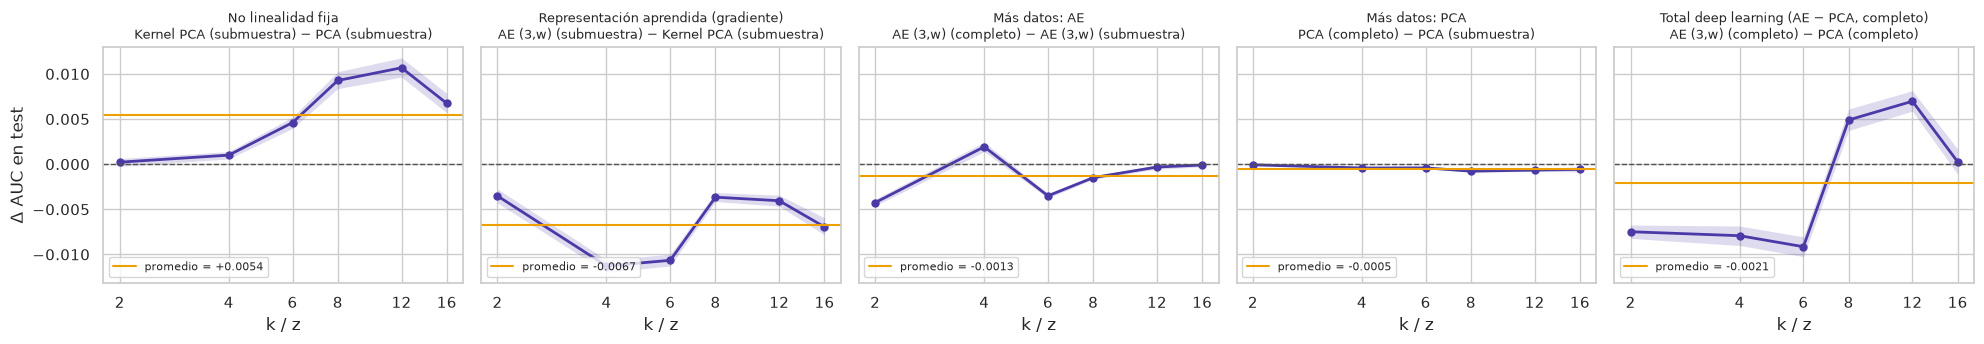

In [22]:
fig, axes = plt.subplots(1, len(APORTES), figsize=(4 * len(APORTES), 3.6), sharey=True)
for ax, (nombre, a, b) in zip(axes, APORTES):
    t = aportes_A_por_k[aportes_A_por_k["aporte"] == nombre]
    resumen = aportes_A.set_index("aporte").loc[nombre]
    ax.fill_between(t["k"], t["ic_2.5"], t["ic_97.5"], color="#4a3aa7", alpha=0.18, linewidth=0)
    ax.plot(t["k"], t["delta"], marker="o", color="#4a3aa7", linewidth=2, markersize=5)
    ax.axhline(0, color="#52514e", linestyle="--", linewidth=1)
    ax.axhline(resumen["delta_promedio"], color="#eda100", linewidth=1.5,
               label=f"promedio = {resumen['delta_promedio']:+.4f}")
    ax.set_xscale("log", base=2)
    ax.set_xticks(GRID_Z)
    ax.set_xticklabels(GRID_Z)
    ax.minorticks_off()
    ax.set_title(f"{nombre}\n{a} − {b}", fontsize=9)
    ax.set_xlabel("k / z")
    ax.legend(fontsize=8, loc="lower left")
axes[0].set_ylabel("Δ AUC en test")
plt.tight_layout()
fig.savefig(FIGURAS_DIR / "aportes_igual_capacidad.png", dpi=200, bbox_inches="tight")
plt.show()

### AUC por categoría de ataque, promediada sobre la rejilla
AUC de normales contra cada categoría, promedio sobre los *k* (y las semillas en el AE). No depende del umbral.

In [23]:
normales = CATEGORIA_TEST == "Normal"
filas = []
for (m, k), errores in ERRORES_A.items():
    fila = {"método": m, "k": k}
    for cat in CATEGORY_ORDER:
        mascara = normales | (CATEGORIA_TEST == cat)
        fila[f"auc_{cat}"] = np.mean([roc_auc_score(CATEGORIA_TEST[mascara] == cat, e[mascara])
                                      for e in errores])
    mascara = normales | NUEVO_TEST
    fila["auc_solo_test"] = np.mean([roc_auc_score(NUEVO_TEST[mascara], e[mascara]) for e in errores])
    filas.append(fila)
categorias_A = pd.DataFrame(filas).groupby("método").mean(numeric_only=True).drop(columns="k").loc[METODOS_A]
categorias_A.to_csv(RESULTADOS_DIR / "igual_capacidad_categorias.csv")
categorias_A.round(4)

,auc_DoS,auc_Probe,auc_R2L,auc_U2R,auc_solo_test
método,,,,,
PCA (completo),0.9630,0.9801,0.9110,0.9382,0.9447
PCA (submuestra),0.9633,0.9805,0.9119,0.9395,0.9453
Kernel PCA (submuestra),0.9727,0.9870,0.9048,0.9570,0.9482
"AE (3,w) (completo)",0.9680,0.9842,0.8833,0.9496,0.9360
"AE (3,w) (submuestra)",0.9689,0.9840,0.8870,0.9488,0.9407


# Diferencia entre validación y test
La validación sale de `KDDTrain+` y test es `KDDTest+`, que está diseñado para ser más difícil. Se cuantifican tres diferencias:
1. **Proporción de ataques.**
2. **Ataques de tipos que no aparecen en el train**: no puede haberlos en validación, porque validación sale del mismo archivo.
3. **Atajo del one-hot**: el codificador se ajusta solo con normales y usa `handle_unknown="ignore"`, así que un registro con un `protocol_type`, `service` o `flag` que ningún normal usó queda con su bloque one-hot en ceros y es trivialmente anómalo.

Luego se compara la AUC de validación con la de test de todas las configuraciones evaluadas: si la validación anticipara bien el test, los puntos estarían ordenados igual en ambos ejes.

In [24]:
categorias_normales = {c: set(X_train_normal[c]) for c in CAT_COLS}


def con_categoria_nueva(X):
    # True si el registro tiene alguna categoría que ningún normal del train usó
    return np.any([~X[c].isin(categorias_normales[c]).to_numpy() for c in CAT_COLS], axis=0)


tipos_train = set(NSLKDD_train["label"])
filas = []
for nombre, df, X, y in [("validación", NSLKDD_validation, X_val, y_val), ("test", NSLKDD_test, X_test, y_test)]:
    atajo = con_categoria_nueva(X)
    tipo_nuevo = (~df["label"].isin(tipos_train)).to_numpy() & (y == 1)
    filas.append({"conjunto": nombre, "registros": len(y), "% ataques": 100 * y.mean(),
                  "tipos de ataque": df.loc[y == 1, "label"].nunique(),
                  "% ataques de tipos no vistos en train": 100 * tipo_nuevo[y == 1].mean(),
                  "% ataques con categoría nunca vista en normales": 100 * atajo[y == 1].mean(),
                  "normales con categoría nunca vista": int((atajo & (y == 0)).sum())})
brecha = pd.DataFrame(filas).set_index("conjunto")
brecha.to_csv(RESULTADOS_DIR / "brecha_validacion_test.csv")
brecha.round(2)

,registros,% ataques,tipos de ataque,% ataques de tipos no vistos en train,% ataques con categoría nunca vista en normales,normales con categoría nunca vista
conjunto,,,,,,
validación,25195,46.54,20,0.00,31.21,0
test,22544,56.92,37,29.22,10.46,3


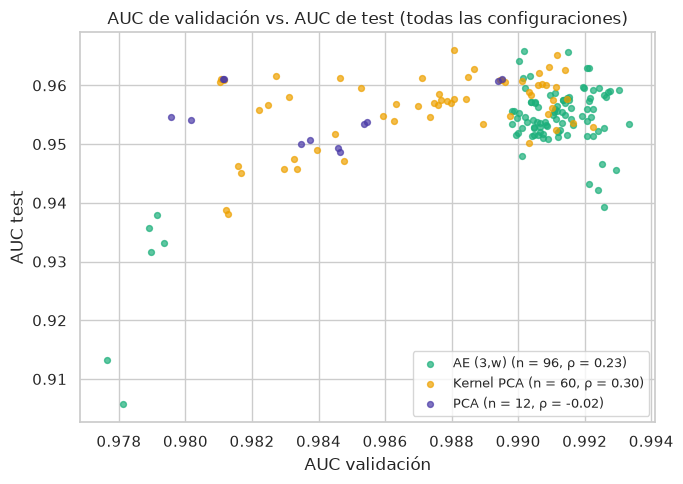

,grupo,configuraciones,spearman_val_test
0,"AE (3,w)",96,0.234
1,Kernel PCA,60,0.298
2,PCA,12,-0.021


In [25]:
from scipy.stats import spearmanr

configs = pd.concat([
    resultados_pca.assign(grupo="PCA"),
    resultados_kpca.assign(grupo="Kernel PCA"),
    corridas_ae.assign(grupo="AE (3,w)"),
], ignore_index=True)

fig, ax = plt.subplots(figsize=(7, 5))
colores_grupo = {"PCA": "#4a3aa7", "Kernel PCA": "#eda100", "AE (3,w)": "#1baf7a"}
filas = []
for grupo, t in configs.groupby("grupo"):
    rho = spearmanr(t["auc_val"], t["auc"]).statistic
    filas.append({"grupo": grupo, "configuraciones": len(t), "spearman_val_test": rho})
    ax.scatter(t["auc_val"], t["auc"], s=18, alpha=0.7, color=colores_grupo[grupo],
               label=f"{grupo} (n = {len(t)}, ρ = {rho:.2f})")
ax.set(title="AUC de validación vs. AUC de test (todas las configuraciones)",
       xlabel="AUC validación", ylabel="AUC test")
ax.legend(fontsize=9)
plt.tight_layout()
fig.savefig(FIGURAS_DIR / "aportes_val_vs_test.png", dpi=200, bbox_inches="tight")
plt.show()
pd.DataFrame(filas).round(3)

# Resultados secundarios: selección por AUC de validación
Se conservan como evidencia de que la selección por validación no es confiable en este problema (ver la sección anterior); las conclusiones se basan en la comparación a igual capacidad.

## Configuración seleccionada de cada método
Todas las selecciones usan solo validación. El AE (5, 64) del notebook anterior se agrega como referencia (semillas 42–46, *z* elegido por AUC de validación en la misma rejilla). Diferencias de protocolo: 100 épocas (~10 600 actualizaciones) sin early stopping.

In [26]:
COLS_TABLA = ["auc_val", "auc", "mcc", "tpr", "fpr", "f1"]
seleccion = {}   # método -> lista de nombres de scores (una por semilla) + fila de métricas

# PCA y kernel PCA: mejor configuración por AUC de validación
for condicion in DATOS:
    r = resultados_pca[resultados_pca["datos"] == condicion]
    mejor = r.loc[r["auc_val"].idxmax()]
    seleccion[f"PCA ({condicion})"] = {"scores": [mejor["scores"]],
                                       "config": f"k={int(mejor['k'])}"}
mejor = resultados_kpca.loc[resultados_kpca["auc_val"].idxmax()]
seleccion["Kernel PCA (submuestra)"] = {
    "scores": [mejor["scores"]],
    "config": f"k={int(mejor['k'])}, γ={mejor['factor_gamma']}·γ0, alpha={mejor['alpha']}"}
KPCA_ELEGIDO = mejor

# AE (3, w): w elegido en la fase 1; z con mayor AUC de validación media sobre semillas
Z_ELEGIDO = {}
for condicion in DATOS:
    r = ae_sel[ae_sel["datos"] == condicion]
    Z_ELEGIDO[condicion] = int(r.groupby("z")["auc_val"].mean().idxmax())
    seleccion[f"AE (3,w) ({condicion})"] = {
        "scores": [nombre_ae(condicion, W_ELEGIDO[condicion], Z_ELEGIDO[condicion], s) for s in SEMILLAS],
        "config": f"w={W_ELEGIDO[condicion]}, z={Z_ELEGIDO[condicion]}"}

filas = []
for metodo, info in seleccion.items():
    metricas = pd.DataFrame([evaluar(*cargar_scores(n)) for n in info["scores"]])
    fila = {"método": metodo, "configuración": info["config"], "semillas": len(info["scores"])}
    for c in COLS_TABLA:
        fila[c] = metricas[c].mean()
    fila["auc_std"] = metricas["auc"].std() if len(metricas) > 1 else np.nan
    filas.append(fila)

# Referencia: AE (5, 64) del notebook anterior
previo = pd.read_csv(Path("resultados") / "ae_nslkdd_corridas.csv")
previo = previo[(previo["estructura"] == "(5,64)") & previo["latente"].isin(GRID_Z)
                & previo["semilla"].isin(SEMILLAS)]
z_previo = int(previo.groupby("latente")["auc_val"].mean().idxmax())
p = previo[previo["latente"] == z_previo]
filas.append({"método": "AE (5,64) (completo, previo)", "configuración": f"z={z_previo}",
              "semillas": len(p), **{c: p[c].mean() for c in COLS_TABLA}, "auc_std": p["auc"].std()})

tabla_seleccion = pd.DataFrame(filas).set_index("método")
tabla_seleccion.to_csv(RESULTADOS_DIR / "seleccion.csv")
tabla_seleccion.round(4)

,configuración,semillas,auc_val,auc,mcc,tpr,fpr,f1,auc_std
método,,,,,,,,,
PCA (completo),k=4,1,0.9894,0.9607,0.6490,0.6539,0.0178,0.7844,NaN
PCA (submuestra),k=4,1,0.9895,0.9612,0.6349,0.6329,0.0150,0.7698,NaN
Kernel PCA (submuestra),"k=16, γ=10.0·γ0, alpha=0.1",1,0.9923,0.9529,0.6155,0.6917,0.0769,0.7906,NaN
"AE (3,w) (completo)","w=64, z=4",5,0.9914,0.9528,0.6662,0.6872,0.0276,0.8042,0.0058
"AE (3,w) (submuestra)","w=64, z=2",5,0.9921,0.9578,0.6819,0.7347,0.0515,0.8284,0.0041
"AE (5,64) (completo, previo)",z=4,5,0.9916,0.9547,0.6646,0.6961,0.0363,0.8073,0.0041


## Desempeño en función de *k* / *z*
Para kernel PCA, en cada *k* se muestra la mejor combinación (γ, alpha) según validación. Para el AE, media ± desviación estándar sobre las semillas con el *w* elegido.

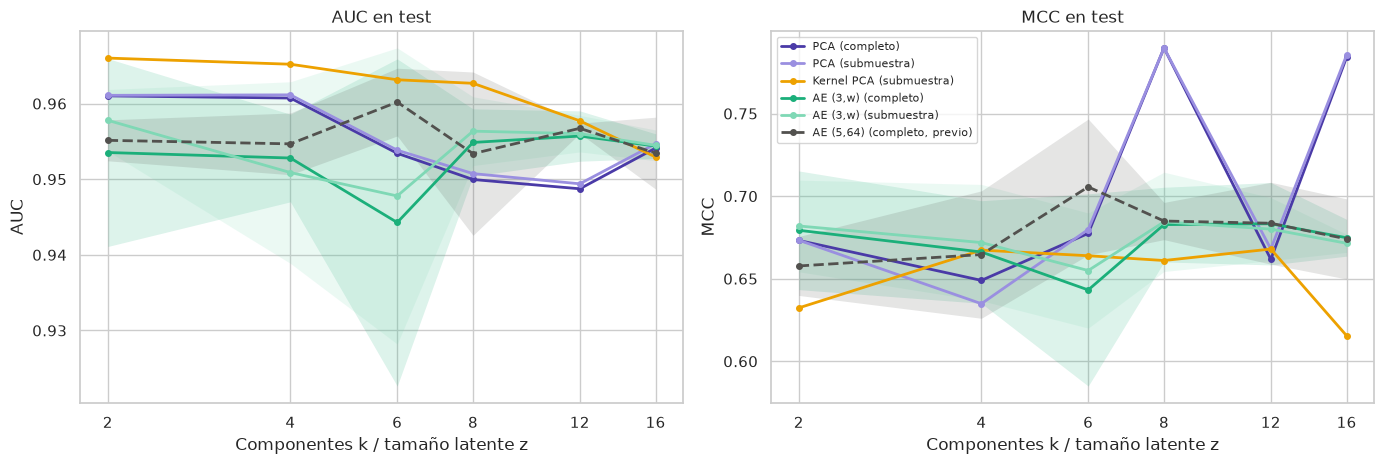

In [27]:
COLORES = {"PCA (completo)": "#4a3aa7", "PCA (submuestra)": "#9a8fe0",
           "Kernel PCA (submuestra)": "#eda100",
           "AE (3,w) (completo)": "#1baf7a", "AE (3,w) (submuestra)": "#7fd8b5",
           "AE (5,64) (completo, previo)": "#52514e"}

curvas = {}
for cond in DATOS:
    r = resultados_pca[resultados_pca["datos"] == cond].set_index("k")
    curvas[f"PCA ({cond})"] = (r[["auc", "mcc"]], None)
mejor_por_k = resultados_kpca.loc[resultados_kpca.groupby("k")["auc_val"].idxmax()].set_index("k")
curvas["Kernel PCA (submuestra)"] = (mejor_por_k[["auc", "mcc"]], None)
for cond in DATOS:
    g = ae_sel[ae_sel["datos"] == cond].groupby("z")[["auc", "mcc"]]
    curvas[f"AE (3,w) ({cond})"] = (g.mean(), g.std())
g = previo.groupby("latente")[["auc", "mcc"]]
curvas["AE (5,64) (completo, previo)"] = (g.mean(), g.std())

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, metrica, titulo in [(axes[0], "auc", "AUC en test"), (axes[1], "mcc", "MCC en test")]:
    for nombre, (media, std) in curvas.items():
        estilo = "--" if "previo" in nombre else "-"
        ax.plot(media.index, media[metrica], estilo, marker="o", color=COLORES[nombre],
                linewidth=2, markersize=4, label=nombre)
        if std is not None:
            ax.fill_between(media.index, media[metrica] - std[metrica], media[metrica] + std[metrica],
                            color=COLORES[nombre], alpha=0.15, linewidth=0)
    ax.set_xscale("log", base=2)
    ax.set_xticks(GRID_Z)
    ax.set_xticklabels(GRID_Z)
    ax.minorticks_off()
    ax.set(title=titulo, xlabel="Componentes k / tamaño latente z", ylabel=metrica.upper())
axes[1].legend(fontsize=8, loc="best")
plt.tight_layout()
fig.savefig(FIGURAS_DIR / "aportes_curvas_kz.png", dpi=200, bbox_inches="tight")
plt.show()

## Aportes: bootstrap pareado
Se remuestrean las filas de test con reemplazo (los **mismos** índices para todos los métodos) y en cada remuestreo se calcula la AUC y el MCC de cada método seleccionado (para el AE, el promedio sobre las 5 semillas). La diferencia entre métodos en cada remuestreo da su distribución: se reporta la estimación con todo el test, el intervalo percentil del 95 % y la proporción de remuestreos en que la diferencia es positiva.

El MCC usa el umbral de cada método fijado en validación, así que también refleja el traslado del umbral, no solo la calidad del *score*.

El AE (5, 64) previo no entra al bootstrap porque no se guardaron sus *scores*.

In [28]:
def preparar(metodo):
    # Errores de test y predicciones (con el umbral de validación) de cada semilla del método
    salida = []
    for nombre in seleccion[metodo]["scores"]:
        err_val, err_test = cargar_scores(nombre)
        umbral, media, std = elegir_umbral(err_val, y_val)
        salida.append((err_test, ((err_test - media) / std > umbral).astype(int)))
    return salida


def mcc_rapido(y, pred):
    tp = np.sum((pred == 1) & (y == 1)); tn = np.sum((pred == 0) & (y == 0))
    fp = np.sum((pred == 1) & (y == 0)); fn = np.sum((pred == 0) & (y == 1))
    denom = math.sqrt(float((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn)))
    return (tp * tn - fp * fn) / denom if denom > 0 else 0.0


METODOS_BOOT = list(seleccion)
datos_boot = {m: preparar(m) for m in METODOS_BOOT}


def metricas_en(idx):
    y = y_test[idx]
    return {m: (np.mean([roc_auc_score(y, e[idx]) for e, _ in datos_boot[m]]),
                np.mean([mcc_rapido(y, p[idx]) for _, p in datos_boot[m]]))
            for m in METODOS_BOOT}


rng = np.random.default_rng(SEED)
completo = metricas_en(np.arange(len(y_test)))
inicio = time.perf_counter()
remuestreos = [metricas_en(rng.integers(0, len(y_test), len(y_test))) for _ in range(N_BOOTSTRAP)]
print(f"Bootstrap: {N_BOOTSTRAP} remuestreos en {time.perf_counter() - inicio:.0f} s")

filas = []
for nombre, a, b in APORTES:
    for i, metrica in enumerate(["AUC", "MCC"]):
        difs = np.array([r[a][i] - r[b][i] for r in remuestreos])
        filas.append({"aporte": nombre, "comparación": f"{a} − {b}", "métrica": metrica,
                      "diferencia": completo[a][i] - completo[b][i],
                      "ic_2.5": np.percentile(difs, 2.5), "ic_97.5": np.percentile(difs, 97.5),
                      "p_positiva": (difs > 0).mean()})
tabla_aportes = pd.DataFrame(filas)
tabla_aportes.to_csv(RESULTADOS_DIR / "aportes_bootstrap.csv", index=False)
tabla_aportes.round(4)

Bootstrap: 1000 remuestreos en 94 s


,aporte,comparación,métrica,diferencia,ic_2.5,ic_97.5,p_positiva
0,No linealidad fija,Kernel PCA (submuestra) − PCA (submuestra),AUC,-0.0082,-0.0095,-0.0070,0.0
1,No linealidad fija,Kernel PCA (submuestra) − PCA (submuestra),MCC,-0.0194,-0.0259,-0.0127,0.0
2,Representación aprendida (gradiente),"AE (3,w) (submuestra) − Kernel PCA (submuestra)",AUC,0.0049,0.0039,0.0058,1.0
3,Representación aprendida (gradiente),"AE (3,w) (submuestra) − Kernel PCA (submuestra)",MCC,0.0664,0.0616,0.0714,1.0
4,Más datos: AE,"AE (3,w) (completo) − AE (3,w) (submuestra)",AUC,-0.0050,-0.0058,-0.0042,0.0
5,Más datos: AE,"AE (3,w) (completo) − AE (3,w) (submuestra)",MCC,-0.0158,-0.0187,-0.0128,0.0
6,Más datos: PCA,PCA (completo) − PCA (submuestra),AUC,-0.0004,-0.0005,-0.0003,0.0
7,Más datos: PCA,PCA (completo) − PCA (submuestra),MCC,0.0141,0.0117,0.0167,1.0
8,"Total deep learning (AE − PCA, completo)","AE (3,w) (completo) − PCA (completo)",AUC,-0.0079,-0.0090,-0.0069,0.0
9,"Total deep learning (AE − PCA, completo)","AE (3,w) (completo) − PCA (completo)",MCC,0.0172,0.0139,0.0204,1.0


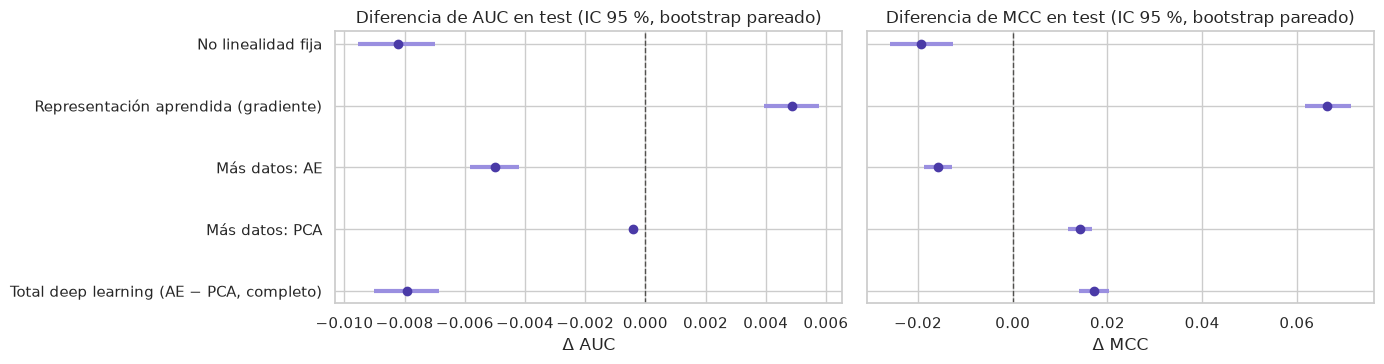

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), sharey=True)
etiquetas = [a for a, _, _ in APORTES]
for ax, metrica in zip(axes, ["AUC", "MCC"]):
    t = tabla_aportes[tabla_aportes["métrica"] == metrica].set_index("aporte").loc[etiquetas]
    y_pos = np.arange(len(t))[::-1]
    ax.errorbar(t["diferencia"], y_pos,
                xerr=[t["diferencia"] - t["ic_2.5"], t["ic_97.5"] - t["diferencia"]],
                fmt="o", color="#4a3aa7", ecolor="#9a8fe0", elinewidth=3, capsize=0, markersize=6)
    ax.axvline(0, color="#52514e", linewidth=1, linestyle="--")
    ax.set_yticks(y_pos)
    ax.set_yticklabels(etiquetas)
    ax.set(title=f"Diferencia de {metrica} en test (IC 95 %, bootstrap pareado)", xlabel=f"Δ {metrica}")
plt.tight_layout()
fig.savefig(FIGURAS_DIR / "aportes_bootstrap.png", dpi=200, bbox_inches="tight")
plt.show()

## Desempeño por categoría de ataque
- **AUC por categoría** (normales contra cada categoría): no depende del umbral, así que es la comparación justa entre métodos.
- **TPR** con el umbral de cada método: depende de la FPR de cada uno (incluida en la tabla).

In [30]:
filas = []
for metodo, info in seleccion.items():
    m = pd.DataFrame([evaluar(*cargar_scores(n)) for n in info["scores"]]).mean(numeric_only=True)
    filas.append({"método": metodo, "fpr": m["fpr"],
                  **{f"auc_{c}": m[f"auc_{c}"] for c in CATEGORY_ORDER},
                  **{f"tpr_{c}": m[f"tpr_{c}"] for c in CATEGORY_ORDER},
                  "tpr_solo_test": m["tpr_solo_test"]})
tabla_categorias = pd.DataFrame(filas).set_index("método")
tabla_categorias.to_csv(RESULTADOS_DIR / "categorias.csv")
tabla_categorias.round(3)

,fpr,auc_DoS,auc_Probe,auc_R2L,auc_U2R,tpr_DoS,tpr_Probe,tpr_R2L,tpr_U2R,tpr_solo_test
método,,,,,,,,,,
PCA (completo),0.018,0.970,0.985,0.914,0.953,0.840,0.798,0.052,0.265,0.528
PCA (submuestra),0.015,0.971,0.985,0.914,0.953,0.825,0.756,0.040,0.140,0.477
Kernel PCA (submuestra),0.077,0.971,0.976,0.886,0.935,0.859,0.940,0.028,0.600,0.611
"AE (3,w) (completo)",0.028,0.972,0.985,0.872,0.957,0.848,0.865,0.113,0.452,0.575
"AE (3,w) (submuestra)",0.051,0.972,0.982,0.899,0.944,0.884,0.899,0.195,0.590,0.675


## Curvas de entrenamiento del AE
AUC de validación por actualización de pesos para el *w* y el *z* elegidos de cada condición (una línea por semilla). Muestra cuándo se detuvo cada corrida y si la condición con submuestra llega a la misma meseta.

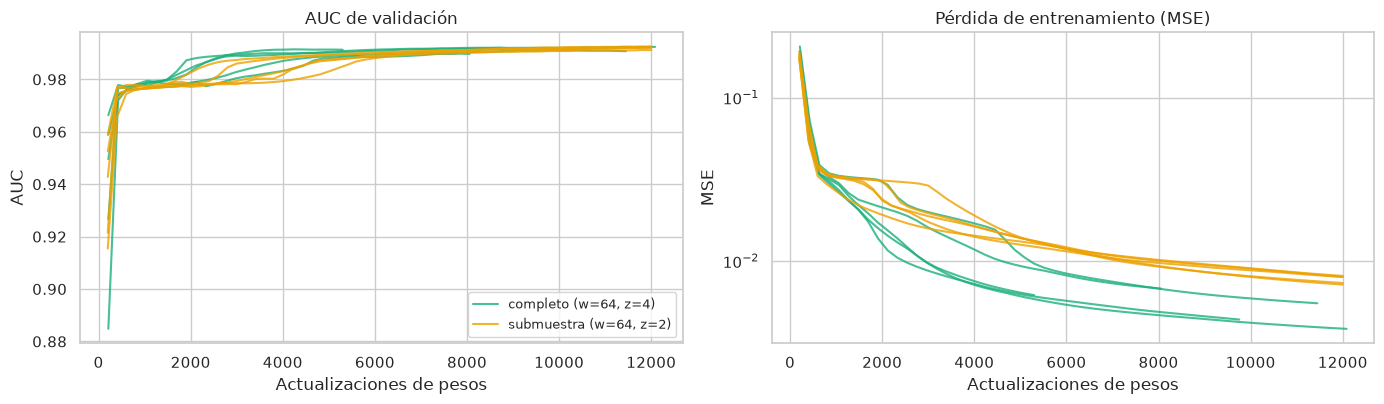

In [31]:
historial = pd.read_csv(HISTORIAL_CSV)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for cond, color in [("completo", "#1baf7a"), ("submuestra", "#eda100")]:
    h = historial[(historial["datos"] == cond) & (historial["w"] == W_ELEGIDO[cond])
                  & (historial["z"] == Z_ELEGIDO[cond])]
    for i, (semilla, hs) in enumerate(h.groupby("semilla")):
        etiqueta = f"{cond} (w={W_ELEGIDO[cond]}, z={Z_ELEGIDO[cond]})" if i == 0 else None
        axes[0].plot(hs["pasos"], hs["auc_val"], color=color, alpha=0.8, linewidth=1.5, label=etiqueta)
        axes[1].plot(hs["pasos"], hs["loss"], color=color, alpha=0.8, linewidth=1.5, label=etiqueta)
axes[0].set(title="AUC de validación", xlabel="Actualizaciones de pesos", ylabel="AUC")
axes[1].set(title="Pérdida de entrenamiento (MSE)", xlabel="Actualizaciones de pesos", ylabel="MSE",
            yscale="log")
axes[0].legend(fontsize=9)
plt.tight_layout()
fig.savefig(FIGURAS_DIR / "aportes_entrenamiento_ae.png", dpi=200, bbox_inches="tight")
plt.show()

## TPR a FPR fijo: configuraciones seleccionadas por validación
Comparación independiente del umbral: para cada método se fija la tasa de falsos positivos (1 % y 5 %) con los errores de los normales de test y se mide la proporción de ataques detectados. Mismo remuestreo pareado de test que en los aportes (AE: promedio de las 5 semillas). El IC no incluye la variación entre semillas. Con FPR = 1 % el umbral depende de unos 100 normales, así que esa columna es mucho más inestable que la de 5 %.

In [ ]:
FPR_OBJETIVO = [0.01, 0.05]
PARES = [("AE (3,w) (submuestra)", "PCA (submuestra)"), ("AE (3,w) (completo)", "PCA (completo)"),
         ("Kernel PCA (submuestra)", "PCA (submuestra)"), ("AE (3,w) (submuestra)", "Kernel PCA (submuestra)")]

# Errores de test de cada semilla de cada método seleccionado
errores = {m: [cargar_scores(n)[1] for n in info["scores"]] for m, info in seleccion.items()}


def tpr_a_fpr(y, err, fpr):
    # Umbral = cuantil (1 - fpr) de los errores de los normales; TPR = ataques por encima del umbral
    umbral = np.quantile(err[y == 0], 1 - fpr)
    return np.mean(err[y == 1] > umbral)


def tprs(idx):
    y = y_test[idx]
    return {(m, f): np.mean([tpr_a_fpr(y, e[idx], f) for e in errs])    # AE: promedio de semillas
            for m, errs in errores.items() for f in FPR_OBJETIVO}


rng = np.random.default_rng(SEED)
completo = tprs(np.arange(len(y_test)))
remuestreos = [tprs(rng.integers(0, len(y_test), len(y_test))) for _ in range(N_BOOTSTRAP)]

filas = []
for m in seleccion:
    fila = {"método": m}
    for f in FPR_OBJETIVO:
        v = np.array([r[(m, f)] for r in remuestreos])
        fila[f"TPR@{f:.0%}"] = completo[(m, f)]
        fila[f"IC@{f:.0%}"] = f"[{np.percentile(v, 2.5):.3f}, {np.percentile(v, 97.5):.3f}]"
    filas.append(fila)
tabla_tpr = pd.DataFrame(filas).set_index("método")

filas = []
for a, b in PARES:
    fila = {"comparación": f"{a} − {b}"}
    for f in FPR_OBJETIVO:
        d = np.array([r[(a, f)] - r[(b, f)] for r in remuestreos])
        fila[f"Δ TPR@{f:.0%}"] = completo[(a, f)] - completo[(b, f)]
        fila[f"IC Δ@{f:.0%}"] = f"[{np.percentile(d, 2.5):+.3f}, {np.percentile(d, 97.5):+.3f}]"
    filas.append(fila)
tabla_dif_tpr = pd.DataFrame(filas).set_index("comparación")

tabla_tpr.to_csv(RESULTADOS_DIR / "tpr_a_fpr_fijo.csv")
tabla_dif_tpr.to_csv(RESULTADOS_DIR / "tpr_a_fpr_fijo_diferencias.csv")
display(tabla_tpr.round(3))
display(tabla_dif_tpr.round(3))

,TPR@1%,IC@1%,TPR@5%,IC@5%
método,,,,
PCA (completo),0.559,"[0.433, 0.593]",0.791,"[0.782, 0.799]"
PCA (submuestra),0.565,"[0.434, 0.596]",0.790,"[0.782, 0.798]"
Kernel PCA (submuestra),0.508,"[0.493, 0.548]",0.627,"[0.618, 0.636]"
"AE (3,w) (completo)",0.436,"[0.399, 0.537]",0.783,"[0.772, 0.792]"
"AE (3,w) (submuestra)",0.523,"[0.469, 0.582]",0.738,"[0.730, 0.745]"


,Δ TPR@1%,IC Δ@1%,Δ TPR@5%,IC Δ@5%
comparación,,,,
"AE (3,w) (submuestra) − PCA (submuestra)",-0.043,"[-0.072, +0.070]",-0.052,"[-0.058, -0.047]"
"AE (3,w) (completo) − PCA (completo)",-0.123,"[-0.142, -0.011]",-0.008,"[-0.016, -0.002]"
Kernel PCA (submuestra) − PCA (submuestra),-0.057,"[-0.082, +0.068]",-0.163,"[-0.170, -0.156]"
"AE (3,w) (submuestra) − Kernel PCA (submuestra)",0.015,"[-0.028, +0.062]",0.110,"[+0.105, +0.116]"


## TPR a FPR fijo a igual capacidad
Mismo cálculo, pero con la rejilla de *k* (igual capacidad) en lugar de las configuraciones elegidas por validación: Kernel PCA con γ = γ0 y alpha = 1 fijados a priori, y el AE con *z* = *k*. Se reporta el promedio sobre *k*, el IC del bootstrap pareado y los *k* ganados (con las estimaciones puntuales). La tercera tabla muestra el TPR@5 % por *k*. El IC no incluye la variación entre semillas.

In [ ]:
FPR_OBJETIVO = [0.01, 0.05]


def tpr_a_fpr(y, err, fprs):
    # Umbral = cuantil (1 - fpr) de los errores de los normales; TPR = ataques por encima del umbral
    umbrales = np.quantile(err[y == 0], [1 - f for f in fprs])
    return [np.mean(err[y == 1] > u) for u in umbrales]


def tpr_por_k(idx):
    # TPR de cada (método, k, FPR) en el remuestreo idx; el AE promedia sus semillas
    y = y_test[idx]
    salida = {}
    for (m, k), errores in ERRORES_A.items():
        por_semilla = np.array([tpr_a_fpr(y, e[idx], FPR_OBJETIVO) for e in errores])
        for j, f in enumerate(FPR_OBJETIVO):
            salida[(m, k, f)] = por_semilla[:, j].mean()
    return salida


def promedio_k(por_k, m, f):
    return np.mean([por_k[(m, k, f)] for k in GRID_Z])


rng = np.random.default_rng(SEED)
completo = tpr_por_k(np.arange(len(y_test)))
remuestreos = [tpr_por_k(rng.integers(0, len(y_test), len(y_test))) for _ in range(N_BOOTSTRAP)]

# TPR promedio sobre k de cada método, con IC
filas = []
for m in METODOS_A:
    fila = {"método": m}
    for f in FPR_OBJETIVO:
        v = np.array([promedio_k(r, m, f) for r in remuestreos])
        fila[f"TPR@{f:.0%}"] = promedio_k(completo, m, f)
        fila[f"IC@{f:.0%}"] = f"[{np.percentile(v, 2.5):.3f}, {np.percentile(v, 97.5):.3f}]"
    filas.append(fila)
tabla_tpr_k = pd.DataFrame(filas).set_index("método")

# Aportes en TPR (misma definición que en la AUC): Δ promedio sobre k, IC y k ganados
filas = []
for nombre, a, b in APORTES:
    fila = {"aporte": nombre}
    for f in FPR_OBJETIVO:
        d = np.array([promedio_k(r, a, f) - promedio_k(r, b, f) for r in remuestreos])
        fila[f"Δ TPR@{f:.0%}"] = promedio_k(completo, a, f) - promedio_k(completo, b, f)
        fila[f"IC Δ@{f:.0%}"] = f"[{np.percentile(d, 2.5):+.3f}, {np.percentile(d, 97.5):+.3f}]"
        fila[f"k ganados@{f:.0%}"] = f"{sum(completo[(a, k, f)] > completo[(b, k, f)] for k in GRID_Z)} de {len(GRID_Z)}"
    filas.append(fila)
tabla_dif_tpr_k = pd.DataFrame(filas).set_index("aporte")

tabla_tpr_k.to_csv(RESULTADOS_DIR / "tpr_igual_capacidad.csv")
tabla_dif_tpr_k.to_csv(RESULTADOS_DIR / "tpr_igual_capacidad_aportes.csv")
por_k = pd.DataFrame([{"método": m, "k": k, **{f"TPR@{f:.0%}": completo[(m, k, f)] for f in FPR_OBJETIVO}}
                      for m in METODOS_A for k in GRID_Z])
por_k.to_csv(RESULTADOS_DIR / "tpr_igual_capacidad_por_k.csv", index=False)
display(tabla_tpr_k.round(3))
display(tabla_dif_tpr_k.round(3))
display(por_k.pivot(index="k", columns="método", values="TPR@5%")[METODOS_A].round(3))

,TPR@1%,IC@1%,TPR@5%,IC@5%
método,,,,
PCA (completo),0.358,"[0.295, 0.384]",0.746,"[0.733, 0.758]"
PCA (submuestra),0.363,"[0.297, 0.388]",0.747,"[0.733, 0.758]"
Kernel PCA (submuestra),0.469,"[0.442, 0.507]",0.773,"[0.763, 0.783]"
"AE (3,w) (completo)",0.483,"[0.420, 0.543]",0.755,"[0.746, 0.764]"
"AE (3,w) (submuestra)",0.505,"[0.443, 0.559]",0.750,"[0.742, 0.758]"


,Δ TPR@1%,IC Δ@1%,k ganados@1%,Δ TPR@5%,IC Δ@5%,k ganados@5%
aporte,,,,,,
No linealidad fija,0.106,"[+0.098, +0.151]",5 de 6,0.026,"[+0.021, +0.033]",4 de 6
Representación aprendida (gradiente),0.035,"[-0.005, +0.060]",5 de 6,-0.022,"[-0.026, -0.019]",1 de 6
Más datos: AE,-0.022,"[-0.028, -0.008]",0 de 6,0.005,"[+0.002, +0.006]",3 de 6
Más datos: PCA,-0.005,"[-0.012, -0.001]",2 de 6,-0.001,"[-0.002, +0.001]",2 de 6
"Total deep learning (AE − PCA, completo)",0.125,"[+0.099, +0.166]",5 de 6,0.009,"[+0.003, +0.016]",3 de 6


método,PCA (completo),PCA (submuestra),Kernel PCA (submuestra),"AE (3,w) (completo)","AE (3,w) (submuestra)"
k,,,,,
2,0.786,0.788,0.761,0.744,0.738
4,0.791,0.790,0.770,0.783,0.759
6,0.691,0.700,0.740,0.738,0.740
8,0.711,0.711,0.754,0.748,0.757
12,0.702,0.705,0.777,0.767,0.760
16,0.794,0.787,0.834,0.749,0.750


## Costo computacional
Medido en la misma GPU para los tres métodos y con la configuración seleccionada:
- **Ajuste:** PCA y kernel PCA, una ejecución con calentamiento previo; AE, media de las semillas (incluye el cálculo de la AUC de validación en cada evaluación).
- **Inferencia:** tiempo de puntuar todo el test (22 544 registros), expresado por registro.
- **Memoria:** valores que el método debe guardar para puntuar registros nuevos (float32). Kernel PCA guarda la submuestra completa y sus coeficientes; el AE, sus pesos.

In [32]:
def cronometrar(funcion, repeticiones=3):
    funcion()                                   # calentamiento (compilación, reserva de memoria)
    tiempos = []
    for _ in range(repeticiones):
        inicio = time.perf_counter()
        funcion()
        tiempos.append(time.perf_counter() - inicio)
    return np.median(tiempos)


filas = []
for cond, X_ajuste in DATOS.items():
    k = int(seleccion[f"PCA ({cond})"]["config"].split("=")[1])
    pca = PCATF().fit(X_ajuste)
    filas.append({"método": f"PCA ({cond})",
                  "seg_ajuste": cronometrar(lambda: PCATF().fit(X_ajuste)),
                  "us_por_registro": cronometrar(lambda: pca.error(X_test_p, k)) / len(X_test_p) * 1e6,
                  "valores_guardados": N_ENTRADA * k + N_ENTRADA})

g, k, a = KPCA_ELEGIDO["gamma"], int(KPCA_ELEGIDO["k"]), KPCA_ELEGIDO["alpha"]


def ajustar_kpca():
    modelo = KernelPCATF(g, k_max=k).fit(X_sub)
    return modelo, modelo.ajustar_preimagen(k, a)


kpca_sel, duales_sel = ajustar_kpca()
filas.append({"método": "Kernel PCA (submuestra)",
              "seg_ajuste": cronometrar(ajustar_kpca, repeticiones=1),
              "us_por_registro": cronometrar(
                  lambda: kpca_sel.error(X_test_p, kpca_sel.proyectar(X_test_p), k, duales_sel),
                  repeticiones=1) / len(X_test_p) * 1e6,
              "valores_guardados": kpca_sel.n_valores_guardados(k)})

for cond in DATOS:
    r = ae_sel[(ae_sel["datos"] == cond) & (ae_sel["z"] == Z_ELEGIDO[cond])]
    filas.append({"método": f"AE (3,w) ({cond})", "seg_ajuste": r["seg_ajuste"].mean(),
                  "us_por_registro": r["seg_inferencia_test"].mean() / len(X_test_p) * 1e6,
                  "valores_guardados": int(r["n_params"].iloc[0])})

tabla_costo = pd.DataFrame(filas).set_index("método")
tabla_costo["memoria_MB"] = tabla_costo["valores_guardados"] * 4 / 1e6
tabla_costo.to_csv(RESULTADOS_DIR / "costo.csv")
tabla_costo.round(3)

,seg_ajuste,us_por_registro,valores_guardados,memoria_MB
método,,,,
PCA (completo),0.022,0.244,385,0.002
PCA (submuestra),0.010,0.258,385,0.002
Kernel PCA (submuestra),9.879,29.359,1870000,7.480
"AE (3,w) (completo)",79.737,54.507,10577,0.042
"AE (3,w) (submuestra)",104.916,20.484,10319,0.041


### Costo frente a rendimiento
Eje Y: puntaje compuesto = 0.4·AUC + 0.4·TPR@5 % + 0.2·TPR@1 %, con promedios sobre *k* a igual capacidad (AUC y TPR a FPR fijo). El costo es el de la configuración seleccionada. Los pesos son una decisión de diseño: la tabla final muestra cuántas veces cada método sería el mejor o quedaría en la frontera con pesos aleatorios. La línea discontinua es la frontera de Pareto: métodos sin otro mejor a la vez en costo y en puntaje.

,auc,TPR@1%,TPR@5%,puntaje
método,,,,
PCA (completo),0.9547,0.3581,0.7458,0.7518
PCA (submuestra),0.9552,0.3633,0.7468,0.7535
Kernel PCA (submuestra),0.9606,0.4692,0.7727,0.7871
"AE (3,w) (completo)",0.9526,0.4830,0.7549,0.7796
"AE (3,w) (submuestra)",0.9539,0.5045,0.7504,0.7826


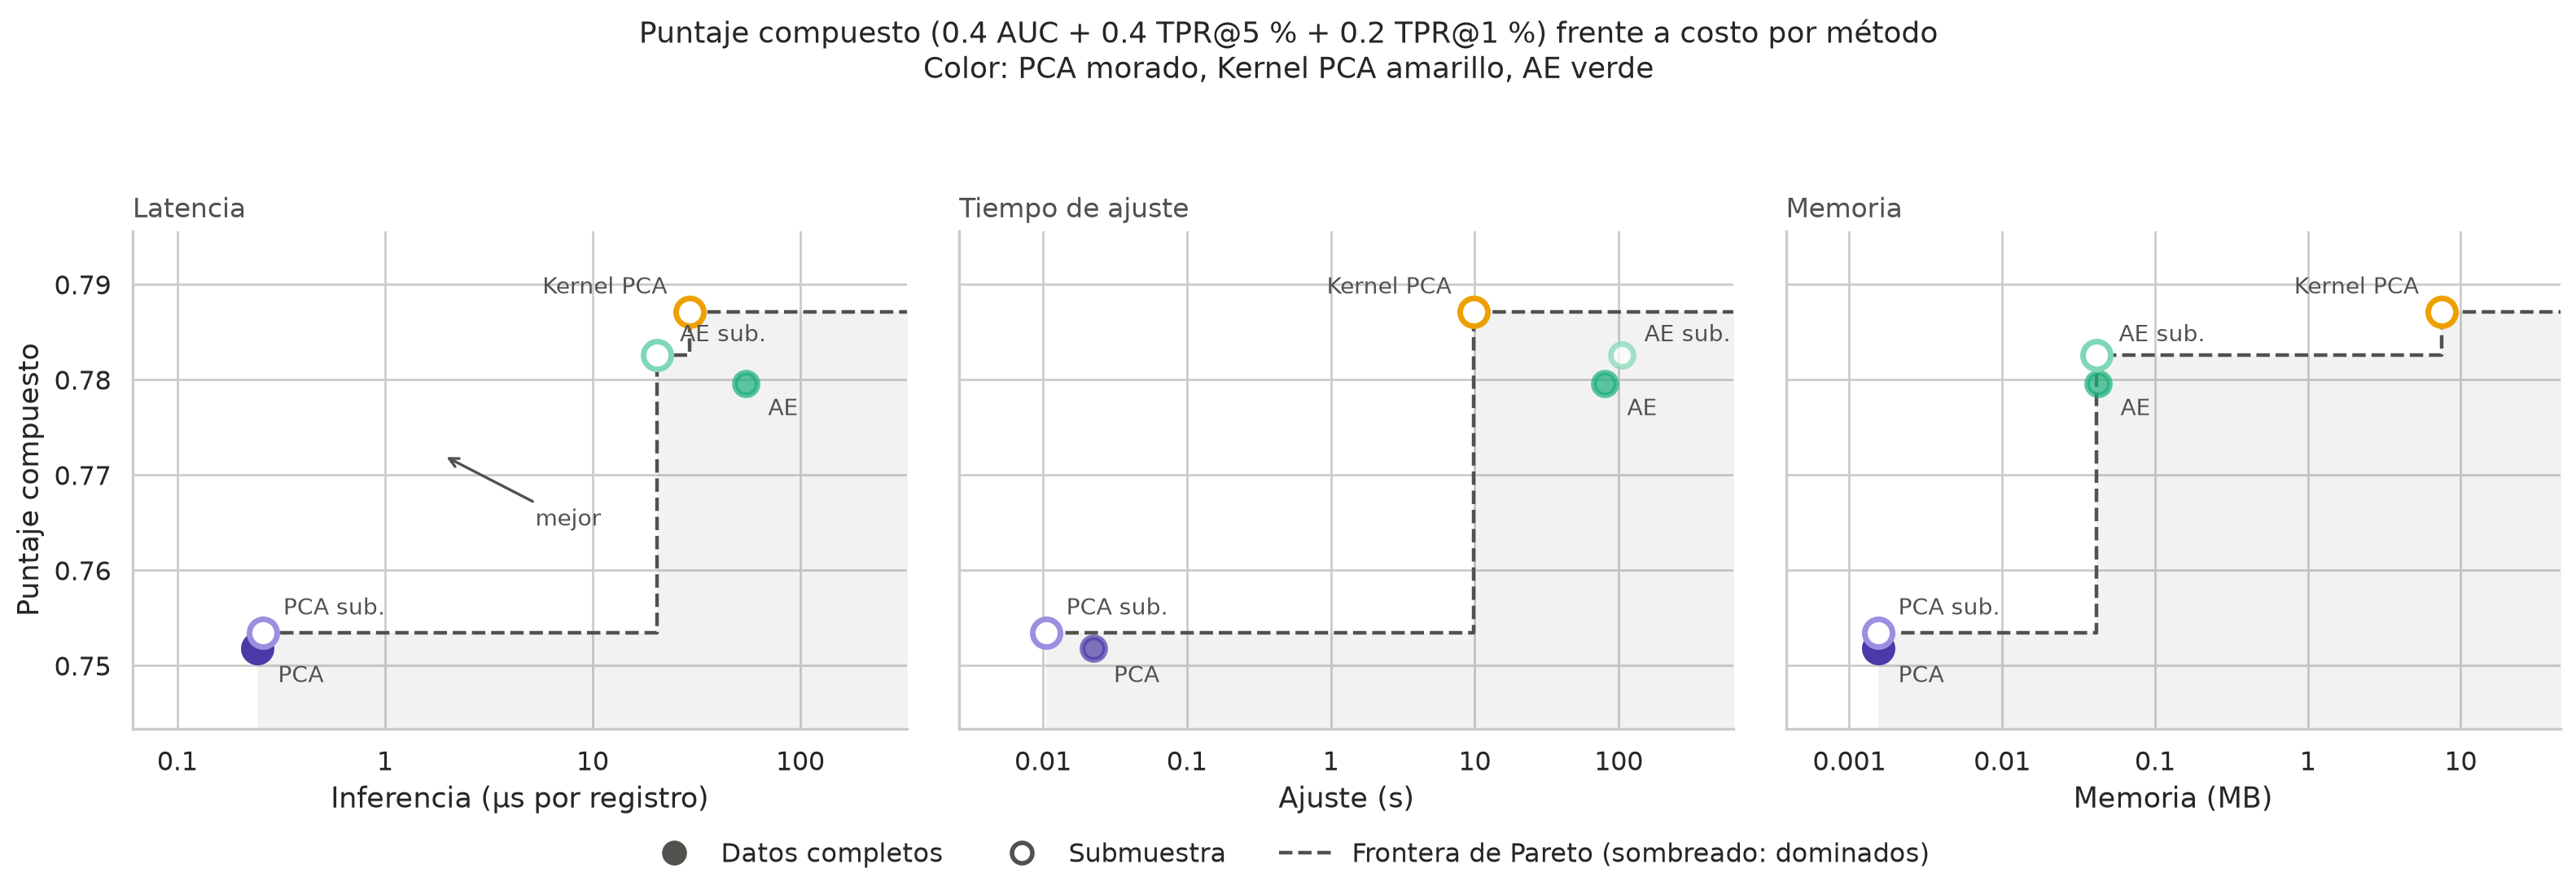

,es el mejor,frontera (us_por_registro),frontera (seg_ajuste),frontera (memoria_MB)
método,,,,
PCA (completo),0.00,1.00,0.00,1.00
PCA (submuestra),0.00,1.00,1.00,1.00
Kernel PCA (submuestra),0.49,0.49,1.00,0.49
"AE (3,w) (completo)",0.00,0.00,0.28,0.14
"AE (3,w) (submuestra)",0.51,1.00,0.51,1.00


In [ ]:
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter, NullFormatter

# Puntaje compuesto a igual capacidad: promedio ponderado de la AUC y del TPR a FPR fijo (promedios sobre k)
PESOS = {"auc": 0.4, "TPR@5%": 0.4, "TPR@1%": 0.2}
metricas = (pd.read_csv(RESULTADOS_DIR / "igual_capacidad_auc.csv").groupby("método")[["auc"]].mean()
            .join(pd.read_csv(RESULTADOS_DIR / "tpr_igual_capacidad.csv").set_index("método")[["TPR@1%", "TPR@5%"]]))
metricas["puntaje"] = sum(p * metricas[m] for m, p in PESOS.items())
metricas = metricas.loc[tabla_costo.index]
datos_costo = tabla_costo.join(metricas["puntaje"].rename("auc"))   # "auc" = eje Y del gráfico
display(metricas.round(4))

PANELES = [("us_por_registro", "Inferencia (µs por registro)", "Latencia"),
           ("seg_ajuste", "Ajuste (s)", "Tiempo de ajuste"),
           ("memoria_MB", "Memoria (MB)", "Memoria")]
# Nombre corto y desplazamiento (puntos) de la etiqueta de cada método
ETIQUETAS = {"PCA (completo)": ("PCA", (9, -15), "left"),
             "PCA (submuestra)": ("PCA sub.", (9, 8), "left"),
             "Kernel PCA (submuestra)": ("Kernel PCA", (-10, 8), "right"),
             "AE (3,w) (completo)": ("AE", (10, -14), "left"),
             "AE (3,w) (submuestra)": ("AE sub.", (10, 6), "left")}
GRIS = "#52514e"


def frontera(x, y):
    # Índices no dominados: ningún otro método tiene a la vez menor costo y mayor AUC
    mejor, idx = -np.inf, []
    for i in np.argsort(x):
        if y[i] > mejor:
            idx.append(i)
            mejor = y[i]
    return idx


with sns.axes_style("whitegrid"), sns.plotting_context("notebook", font_scale=1.05):
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True)
    ymin, ymax = datos_costo["auc"].min(), datos_costo["auc"].max()
    margen = 0.12 * (ymax - ymin)
    for ax, (col, xlabel, titulo) in zip(axes, PANELES):
        x, y = datos_costo[col].to_numpy(), datos_costo["auc"].to_numpy()
        f = frontera(x, y)
        xf = list(x[f]) + [x.max() * 1e3]        # la frontera se prolonga a la derecha (el eje la recorta)
        yf = list(y[f]) + [y[f][-1]]
        ax.fill_between(xf, ymin - 3 * margen, yf, step="post", color=GRIS, alpha=0.07, lw=0)
        ax.step(xf, yf, where="post", color=GRIS, lw=1.6, ls="--", zorder=2)
        for i, (nombre, fila) in enumerate(datos_costo.iterrows()):
            color, completo = COLORES[nombre], "completo" in nombre
            en_frontera = i in f
            ax.scatter(fila[col], fila["auc"], s=150 if en_frontera else 100, marker="o", zorder=3,
                       facecolor=color if completo else "white", edgecolor=color,
                       linewidth=2.5, alpha=1 if en_frontera else 0.7)
            texto, desplazamiento, ha = ETIQUETAS[nombre]
            ax.annotate(texto, (fila[col], fila["auc"]), textcoords="offset points",
                        xytext=desplazamiento, ha=ha, fontsize=10, color=GRIS)
        ax.set_xscale("log")
        ax.set_xlim(x.min() / 4, x.max() * 6)
        ax.set_ylim(ymin - 2 * margen, ymax + 2 * margen)
        ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
        ax.xaxis.set_minor_formatter(NullFormatter())
        ax.set_xlabel(xlabel)
        ax.set_title(titulo, fontsize=12, loc="left", color=GRIS)
    axes[0].set_ylabel("Puntaje compuesto")
    axes[0].annotate("mejor", xy=(0.40, 0.55), xytext=(0.52, 0.42), xycoords="axes fraction",
                     fontsize=10, color=GRIS, va="center", ha="left",
                     arrowprops=dict(arrowstyle="->", color=GRIS, lw=1.2))
    leyenda = [Line2D([], [], marker="o", ls="", ms=9, mfc=GRIS, mec=GRIS, mew=2, label="Datos completos"),
               Line2D([], [], marker="o", ls="", ms=9, mfc="white", mec=GRIS, mew=2, label="Submuestra"),
               Line2D([], [], color=GRIS, ls="--", lw=1.6, label="Frontera de Pareto (sombreado: dominados)")]
    fig.legend(handles=leyenda, loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.06))
    fig.suptitle("Puntaje compuesto (0.4 AUC + 0.4 TPR@5 % + 0.2 TPR@1 %) frente a costo por método\nColor: PCA morado, Kernel PCA amarillo, AE verde", y=1.06, fontsize=13)
    sns.despine()
    plt.tight_layout()
    fig.savefig(FIGURAS_DIR / "aportes_costo.png", dpi=200, bbox_inches="tight")
    plt.show()

# Sensibilidad a los pesos: con pesos aleatorios (Dirichlet), ¿cuántas veces cada método es el mejor o queda en la frontera?
rng = np.random.default_rng(SEED)
M = metricas[["auc", "TPR@5%", "TPR@1%"]].to_numpy()
costos = {c: tabla_costo.loc[metricas.index, c].to_numpy() for c, _, _ in PANELES}
mejor = np.zeros(len(M)); en_front = {c: np.zeros(len(M)) for c in costos}
SORTEOS = 5000
for w in rng.dirichlet(np.ones(3), SORTEOS):
    p = M @ w
    mejor[np.argmax(p)] += 1
    for c, x in costos.items():
        en_front[c][frontera(x, p)] += 1
sensibilidad = pd.DataFrame({"es el mejor": mejor / SORTEOS,
                             **{f"frontera ({c})": v / SORTEOS for c, v in en_front.items()}}, index=metricas.index)
sensibilidad.to_csv(RESULTADOS_DIR / "puntaje_sensibilidad.csv")
display(sensibilidad.round(2))

### Perfil de cada método (radar)
Complemento del Pareto: muestra el perfil, no la decisión. Desempeño a igual capacidad (AUC, TPR@5 %, TPR@1 %, promedios sobre *k*) en escala absoluta (AUC de 0.5 a 1; TPR de 0 a 1), de modo que las diferencias pequeñas se ven pequeñas. Los costos (configuración seleccionada) se expresan en veces el costo de PCA (submuestra), en escala logarítmica: el borde es 1× y el centro, 10 000×. El área del polígono no es una medida de calidad.

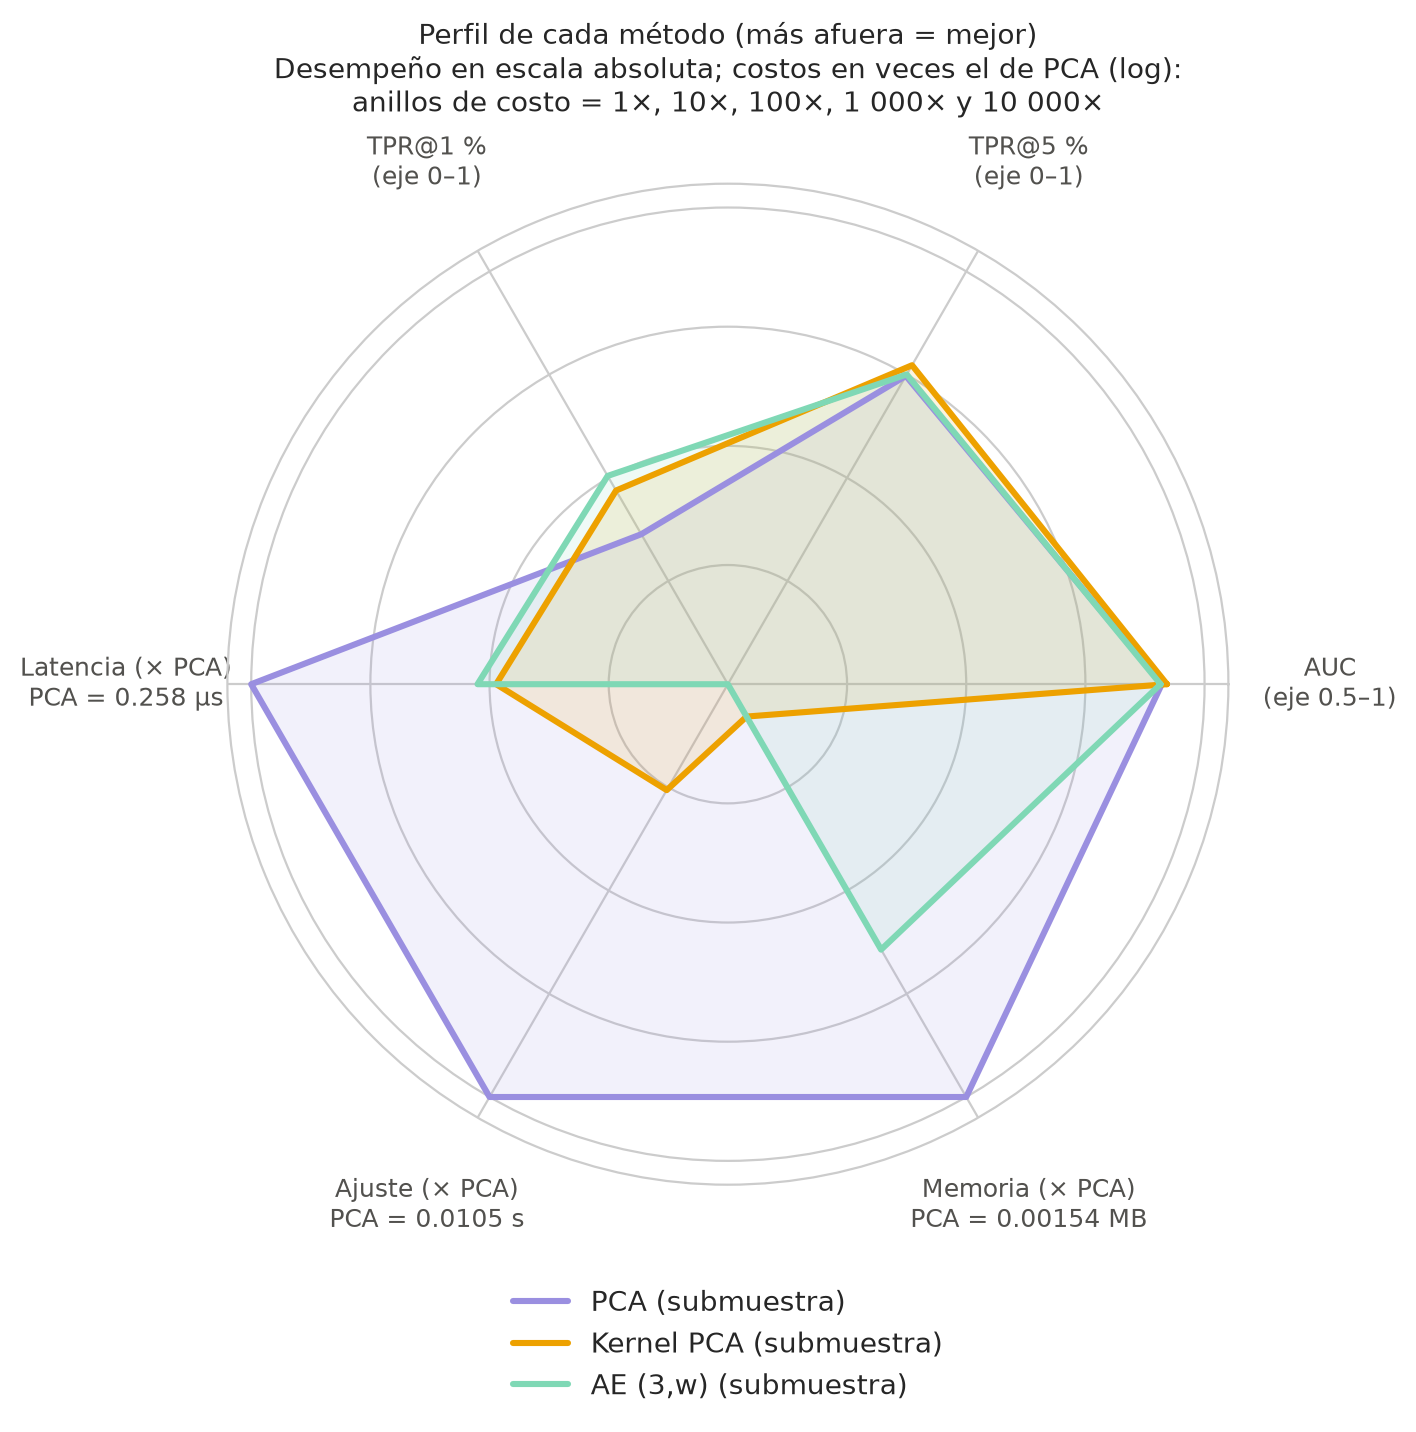

In [ ]:
METODOS_RADAR = ["PCA (submuestra)", "Kernel PCA (submuestra)", "AE (3,w) (submuestra)"]
REFERENCIA = "PCA (submuestra)"
DECADAS = 4        # el centro del radar equivale a 10^4 veces el costo de PCA
EJES = [("AUC", "auc", ""), ("TPR@5 %", "TPR@5%", ""), ("TPR@1 %", "TPR@1%", ""),
        ("Latencia", "us_por_registro", " µs"), ("Ajuste", "seg_ajuste", " s"), ("Memoria", "memoria_MB", " MB")]
COSTOS = {"us_por_registro", "seg_ajuste", "memoria_MB"}

# Desempeño a igual capacidad (promedio sobre k) y costo de la configuración seleccionada
base = (pd.read_csv(RESULTADOS_DIR / "igual_capacidad_auc.csv").groupby("método")[["auc"]].mean()
        .join(pd.read_csv(RESULTADOS_DIR / "tpr_igual_capacidad.csv").set_index("método")[["TPR@1%", "TPR@5%"]])
        .join(pd.read_csv(RESULTADOS_DIR / "costo.csv").set_index("método")[["us_por_registro", "seg_ajuste", "memoria_MB"]]))

# Escalas absolutas (no dependen de los métodos comparados):
#   AUC: 0.5 (azar) -> 0, 1 -> 1;  TPR: 0 -> 0, 1 -> 1
#   costo: veces el de PCA en escala log; 1x (borde) -> 1, 10^DECADAS x (centro) -> 0
norm = pd.DataFrame(index=base.index)
norm["auc"] = (base["auc"] - 0.5) / 0.5
norm["TPR@5%"], norm["TPR@1%"] = base["TPR@5%"], base["TPR@1%"]
for col in COSTOS:
    veces = base[col] / base.loc[REFERENCIA, col]
    norm[col] = (1 - np.log10(veces) / DECADAS).clip(0, 1)

etiquetas = [f"{n}\n(eje 0.5–1)" if c == "auc" else f"{n}\n(eje 0–1)" if c not in COSTOS
             else f"{n} (× PCA)\nPCA = {base.loc[REFERENCIA, c]:.3g}{u}" for n, c, u in EJES]
angulos = np.linspace(0, 2 * np.pi, len(EJES), endpoint=False)

with sns.axes_style("whitegrid"):
    fig, ax = plt.subplots(figsize=(6.5, 6.5), subplot_kw={"projection": "polar"})
    for m in METODOS_RADAR:
        vals = norm.loc[m, [c for _, c, _ in EJES]].to_numpy()
        ax.plot(np.append(angulos, angulos[0]), np.append(vals, vals[0]), color=COLORES[m], lw=2.2, label=m)
        ax.fill(np.append(angulos, angulos[0]), np.append(vals, vals[0]), color=COLORES[m], alpha=0.12)
    ax.set_xticks(angulos)
    ax.set_xticklabels(etiquetas, fontsize=9, color="#52514e")
    ax.tick_params(axis="x", pad=26)
    ax.set_yticks([0.25, 0.5, 0.75, 1])
    ax.set_yticklabels([])
    ax.set_ylim(0, 1.05)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=1, frameon=False)
    ax.set_title("Perfil de cada método (más afuera = mejor)\nDesempeño en escala absoluta; costos en veces el de PCA (log):\n"
                 "anillos de costo = 1×, 10×, 100×, 1 000× y 10 000×", fontsize=10, pad=26)
    fig.savefig(FIGURAS_DIR / "aportes_radar.png", dpi=200, bbox_inches="tight")
    plt.show()

## Proyecciones: UMAP de cada espacio comprimido
Submuestra de test de 6 000 registros estratificada por categoría (como en el notebook anterior). Cada espacio comprimido se lleva a 2D con UMAP, que no usa las etiquetas: solo sirven para colorear.

UMAP deforma las distancias. La figura muestra cómo se agrupan los datos en cada espacio; la capacidad de detección la dicen las métricas.

/home/yeiver/.venvs/deeplearning/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 18 variables. 
  saveable.load_own_variables(store)


/home/yeiver/.venvs/deeplearning/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/home/yeiver/.venvs/deeplearning/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/home/yeiver/.venvs/deeplearning/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


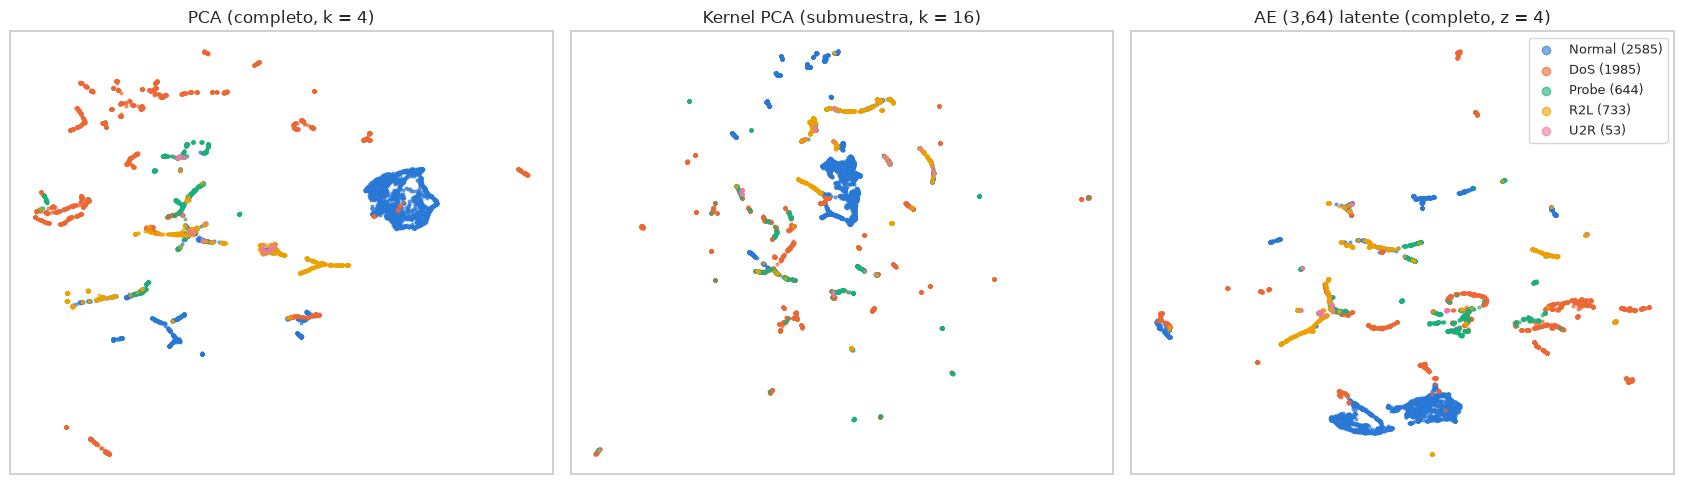

In [33]:
import umap

CLASS_PALETTE = {"Normal": "#2a78d6"}
CATEGORY_PALETTE = {"DoS": "#eb6834", "Probe": "#1baf7a", "R2L": "#eda100", "U2R": "#e87ba4"}
COLORES_VIZ = {**CLASS_PALETTE, **CATEGORY_PALETTE}

idx_muestra, _ = train_test_split(np.arange(len(y_test)), train_size=min(6000, len(y_test) - 10),
                                  stratify=CATEGORIA_TEST, random_state=SEED)
categoria_muestra = CATEGORIA_TEST[idx_muestra]

k_pca = int(seleccion["PCA (completo)"]["config"].split("=")[1])
espacios = {f"PCA (completo, k = {k_pca})": PCATF().fit(X_completo).proyectar(X_test_p[idx_muestra], k_pca),
            f"Kernel PCA (submuestra, k = {k})": kpca_sel.proyectar(X_test_p[idx_muestra])[:, :k]}

w_c, z_c = W_ELEGIDO["completo"], Z_ELEGIDO["completo"]
keras.backend.clear_session()
ae_viz = construir_autoencoder(N_ENTRADA, 3, w_c, z_c)
ae_viz.load_weights(MODELOS_DIR / f"{nombre_ae('completo', w_c, z_c, SEED)}.weights.h5")
encoder = Model(ae_viz.input, ae_viz.get_layer("latente").output)
espacios[f"AE (3,{w_c}) latente (completo, z = {z_c})"] = encoder.predict(
    X_test_p[idx_muestra], batch_size=4096, verbose=0)

proyecciones = {nombre: umap.UMAP(n_neighbors=30, min_dist=0.1, random_state=SEED).fit_transform(E)
                for nombre, E in espacios.items()}

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, (nombre, emb) in zip(axes, proyecciones.items()):
    for cat in ["Normal"] + CATEGORY_ORDER:
        m = categoria_muestra == cat
        ax.scatter(emb[m, 0], emb[m, 1], s=4, alpha=0.6, color=COLORES_VIZ[cat], label=f"{cat} ({m.sum()})")
    ax.set(title=nombre, xticks=[], yticks=[])
axes[2].legend(markerscale=3, fontsize=9, loc="best")
plt.tight_layout()
fig.savefig(FIGURAS_DIR / "aportes_umap.png", dpi=200, bbox_inches="tight")
plt.show()

## Resumen del desempeño
AUC de cada método a igual capacidad (promedio sobre *k*). Las barras de error son el IC del 95 % del bootstrap pareado de test y no incluyen la variación entre semillas del AE. El eje parte de 0.5 (azar).

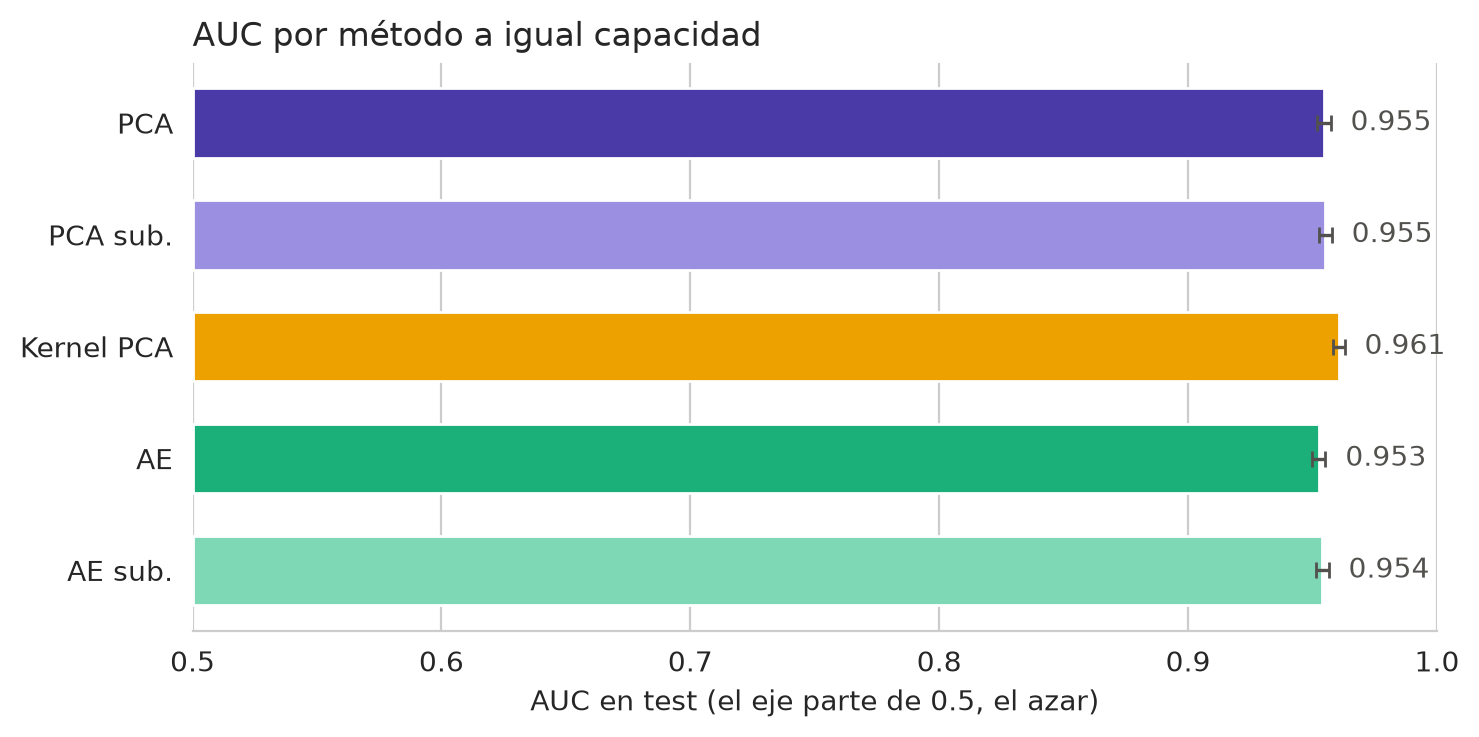

In [ ]:
# AUC promedio sobre k con su IC del 95 % (bootstrap pareado ya calculado)
auc_ic = []
for m in METODOS_A:
    medias = np.array([np.mean([r[(m, k)] for k in GRID_Z]) for r in remuestreos_A])
    auc_ic.append({"método": m, "AUC": np.mean([auc_completo_test[(m, k)] for k in GRID_Z]),
                   "ic_bajo": np.percentile(medias, 2.5), "ic_alto": np.percentile(medias, 97.5)})
auc_ic = pd.DataFrame(auc_ic).set_index("método")
auc_ic.to_csv(RESULTADOS_DIR / "auc_igual_capacidad_ic.csv")

# --- Gráfico ---
NOMBRES = {"PCA (completo)": "PCA", "PCA (submuestra)": "PCA sub.", "Kernel PCA (submuestra)": "Kernel PCA",
           "AE (3,w) (completo)": "AE", "AE (3,w) (submuestra)": "AE sub."}
valor, bajo, alto = auc_ic["AUC"].loc[METODOS_A], auc_ic["ic_bajo"].loc[METODOS_A], auc_ic["ic_alto"].loc[METODOS_A]

with sns.axes_style("whitegrid"):
    fig, ax = plt.subplots(figsize=(7.5, 3.8))
    y = np.arange(len(METODOS_A))[::-1]
    ax.barh(y, valor - 0.5, left=0.5, height=0.62, color=[COLORES[m] for m in METODOS_A], zorder=2)
    ax.errorbar(valor, y, xerr=[valor - bajo, alto - valor], fmt="none", ecolor="#52514e",
                elinewidth=1.2, capsize=3, zorder=3)
    for yi, m in zip(y, METODOS_A):
        ax.text(alto[m] + 0.008, yi, f"{valor[m]:.3f}", va="center", fontsize=10, color="#52514e")
    ax.set_yticks(y)
    ax.set_yticklabels([NOMBRES[m] for m in METODOS_A])
    ax.set_xlim(0.5, 1.0)
    ax.set_xlabel("AUC en test (el eje parte de 0.5, el azar)")
    ax.set_title("AUC por método a igual capacidad", loc="left", fontsize=12)
    ax.grid(axis="y", visible=False)
    sns.despine(left=True)
    plt.tight_layout()
    fig.savefig(FIGURAS_DIR / "aportes_desempeno.png", dpi=200, bbox_inches="tight")
    plt.show()

# Interpretación


**1. No linealidad fija: Kernel PCA frente a PCA.** Kernel PCA obtiene una AUC superior a la de PCA y la diferencia es estadísticamente significativa (Δ = +0.005; el IC del 95 % no incluye el cero). El signo se mantiene en los seis valores de *k*, aunque en *k* = 2 el IC incluye el cero. La categoría con mayor diferencia es U2R, pero tiene pocos ejemplos en test, por lo que ese resultado debe leerse con cautela.

**2. Aprendizaje por gradiente: AE frente a Kernel PCA.** A igual capacidad, el AE pierde frente a Kernel PCA: Δ AUC = −0.007 (−0.0067), con un IC del 95 % que no incluye el cero. Con los mismos datos y la misma estructura, aprender la representación por gradiente no supera a fijarla con un kernel.

**3. Efecto de los datos adicionales y escalabilidad.** Los datos adicionales no mejoran a ninguno de los dos métodos: con el conjunto completo la AUC baja ligeramente tanto en el AE (−0.0013) como en PCA (−0.0005). PCA casi no cambia, porque con la submuestra ya estima bien la covarianza; el AE es algo más sensible y en la dirección equivocada. Esto no respalda la escalabilidad como ventaja del deep learning en este experimento, pues se esperaría que el AE mejorara más que PCA al crecer los datos. Hipótesis (no verificada): con una normalidad más diversa (más servicios y protocolos), el AE reconstruye mejor también los ataques y el contraste del error entre tráfico normal y ataque se reduce; no sería sobreajuste, sino una generalización excesiva de la reconstrucción.

**4. Profundidad del autoencoder.** El AE (5,64) y el AE (3,64) no se separan en test: la AUC es 0.9547 frente a 0.9528 (+0.0019), una diferencia dentro de la variación entre semillas. La profundidad aporta una capacidad predictiva marginal, lo que coincide con Song et al. (2021), quienes tampoco encuentran efecto de la profundidad. Sin embargo, los protocolos difieren (número de épocas y *early stopping*), por lo que el efecto de la profundidad no queda completamente confirmado.

**5. Costo computacional y viabilidad en tiempo real.** PCA es, con diferencia, el método más barato: se ajusta en 0.02 s, puntúa en 0.24 µs por registro y guarda 0.0015 MB. Kernel PCA mejora la AUC en +0.005 y el TPR en +0.026 a FPR = 5 % (+0.106 a FPR = 1 %), pero con un costo muy superior (9.9 s de ajuste, 29 µs por registro y 7.5 MB), que además crece con el tamaño de la submuestra. El AE no mejora la AUC frente a PCA (−0.002) y gana +0.009 de TPR a FPR = 5 % (+0.125 a FPR = 1 %), a cambio de 80–105 s de ajuste (offline, en cada entrenamiento) y 20–54 µs por registro. La mejora de desempeño es pequeña (salvo a FPR = 1 %) frente a costos de varios órdenes de magnitud, por lo que el costo adicional no se justifica y, para un NIDS en tiempo real, el método viable es PCA. Limitaciones: las implementaciones son distintas y Kernel PCA se midió con una sola repetición.

**6. AUC frente a MCC: sensibilidad de las conclusiones a la métrica.** Las conclusiones cambian según la métrica porque el MCC y el F1 dependen del umbral fijado en validación y la AUC no. Con las configuraciones elegidas por validación, el AE obtiene el mayor MCC (0.682) y F1 (0.828), pero opera a otro FPR (0.051 frente a 0.018 de PCA), de modo que parte de su ventaja proviene de la calibración del umbral. Al excluir el umbral (TPR a FPR fijo, a igual capacidad y promediado sobre *k*), Kernel PCA es el mejor a FPR = 5 % (0.773 frente a 0.746 de PCA; IC de la diferencia [+0.021, +0.033]) y el AE queda en un punto intermedio (≈ 0.75). A FPR = 1 % el AE supera a PCA (0.48–0.50 frente a 0.36) sin separarse de Kernel PCA. Además, PCA es el más sensible a *k* (TPR@5 % entre 0.69 y 0.79) y el AE el más estable (0.74–0.78), por lo que el buen resultado de PCA con el *k* elegido por validación (*k* = 4) depende de esa elección. En conclusión, ninguna métrica decide por sí sola: la elección debe combinar AUC, desempeño a FPR fijo y costo.

**7. Selección por validación y brecha entre validación y test.** Si hubiéramos confiado en la AUC de validación para elegir los hiperparámetros, habríamos llegado a conclusiones distintas, e incluso opuestas, en dos de los aportes. La causa es la saturación de la AUC de validación: todos los métodos alcanzan muy pronto valores cercanos a 0.99, las diferencias entre configuraciones son mínimas y dependen más de la semilla y del azar que de la calidad real, y elegir el máximo entre muchas configuraciones con una métrica así es poco fiable (la correlación entre validación y test es baja).

La brecha se explica porque la validación es más fácil que el test. Proviene de la misma distribución que el entrenamiento, contiene muchos ataques triviales de detectar por el atajo del *one-hot* y no incluye tipos de ataque nuevos; el test sí los incluye y tiene menos ataques triviales. Por eso la validación no mide la capacidad de generalizar a ataques no vistos.

**Cómo se evitó la fuga de información.** Ningún hiperparámetro ni umbral se eligió con el test. En la selección "por validación" (*k*, γ, alpha, ancho, *z*, punto de parada del AE y umbral) solo se usó el conjunto de validación; el test se usó únicamente para reportar resultados y diagnosticar la brecha. La comparación a igual capacidad no elige nada: fija γ y alpha de antemano, recorre toda la rejilla de *k* y promedia, así que su resultado no depende de una elección hecha con el test. Limitación: la decisión de adoptar ese diseño surgió después de observar la brecha entre validación y test; no se eligió ninguna configuración con ella, pero el diseño no estaba fijado de antemano.

## Limitaciones

- **Un solo conjunto de datos.** Los resultados son de NSL-KDD y pueden no extenderse a otros datos de tráfico.
- **Incertidumbre incompleta.** Los intervalos del bootstrap solo recogen la variación de la muestra de test; no incluyen la variación entre semillas del AE ni la de otros particionamientos.
- **Validación más fácil que test.** La validación comparte distribución con el entrenamiento, contiene ataques triviales por el atajo del *one-hot* y no incluye tipos de ataque nuevos; por eso orienta poco la elección de configuraciones.
- **Ventaja del AE en la selección.** El AE elige su mejor punto de entrenamiento (y el ancho *w* = 64) con las etiquetas de validación; PCA y Kernel PCA no tienen ese grado de libertad.
- **Umbrales.** El umbral del MCC y del F1 se fija con las etiquetas de validación. El TPR a FPR fijo calcula el umbral con los normales de test, así que describe puntos de la curva ROC y no un umbral desplegable.
- **Preprocesamiento.** Se ajusta con todos los datos normales, incluso en las condiciones con submuestra.
- **Kernel PCA.** Sus hiperparámetros (γ y alpha) se fijaron a priori y no se estudió su sensibilidad; los resultados pueden cambiar con otros valores. Se calculó en *float32*, verificado contra scikit-learn en una muestra pequeña.
- **Profundidad.** El AE (5,64) previo usa otro protocolo (100 épocas, sin *early stopping*) y no tiene *scores* guardados, por lo que no entra al bootstrap.
- **Costos.** Las implementaciones son distintas y Kernel PCA se midió con una sola repetición. Los costos son de la configuración seleccionada.
- **Puntaje compuesto.** Sus pesos son una decisión de diseño; sirve para resumir, no como medida objetiva.

## Uso declarado de IA

Estos experimentos se implementaron utilizando Claude Opus 5.5.

Las tareas en las que se uso claude fueron principalmente en la redaccion del codigo de generacion de algunas graficas presentadas en el cuaderno.

Ej: Prompt: Implementa un grafico de radar, presentando las metricas analziadas y el inverso de los costos, para poder evaluar el perfil de cada herramienta. Normaliza el valor de cada eje para poder hacer una comparacion visual honesta y adecuada.


Otras tareas en las que la IA participo fue en la revision de la redaccion y ortografia. Investigacion de literatura. Propuestas metodologicas de contraste, como el control de TPR y FPR fijo.

Las respuestas de claude fueron analizadas, evaluadas y modificadas, y el contenido final fue curado y evaluado por Yeiver Sanabria.
